# **Introduction**

<div style = "text-align: justify;">

This project aims to build a machine learning–driven **lead evaluation** system for Swan Chemical Ltd., a leading adhesive manufacturer. The evaluator is prepared as a **MVP** (Minimum Viable Product) to classify incoming company inquiries into actionable lead buckets (Hot, Warm, Cold, Save For Later, Reject) and generate a probability-based lead score to support sales prioritization. The project encompasses data preprocessing, exploratory data analysis, model training and evaluation, hyperparameter tuning, and final model selection. The ultimate goal is to provide Swan Chemical Ltd. with a robust tool that enhances their lead management process and drives business growth.

The dataset used in this project is a synthetic dataset created to mimic real-world lead evaluation scenarios. It contains various features related to company inquiries, such as company size, industry, inquiry source, and historical interaction data. The target variable is the **lead bucket** classification which indicates the potential value of each lead and **lead score**, which assigns a score based on the predicted probabilities of the lead belonging to each bucket.

## Aims & Objectives

<div style="text-align: justify;">

### **Aim**
To help Swan Chemical Ltd. **identify and prioritize high-potential adhesive customers** by sorting every incoming company lead into **Hot**, **Warm**, **Cold**, **Save For Later**, or **Reject**, with a lead score to guide sales follow-up.

### **Broad Objective**
To build a machine learning–driven **lead evaluation system** that classifies incoming inquiries into actionable lead buckets and turns the model's probabilities into a simple score and recommended action for the sales team.

### **Specific Objectives**
1. To prepare the lead dataset by encoding ordinal and nominal features inside a **pipeline**, so preprocessing is learned from training data only and never leaks into validation or test data.
2. To compare five multi-class models (**Logistic Regression, Random Forest, LightGBM, CatBoost, HistGradientBoosting**) using **Macro F1**, cross-validation stability, and ROC-AUC (OVR and Qualified-vs-Not).
3. To select the strongest model on cross-validation and **tune it with Optuna** to reduce overfitting, keeping the test set for the final evaluation only.
4. To explain the final model with **feature importance and SHAP**, showing which lead signals drive its predictions.
5. To convert probabilities into a **QualifiedScore** (P(Hot) + P(Warm)) with actions (prioritize, nurture, deprioritize), and deploy the model as a **saved pipeline and scoring script** that checks incoming data.

</div>

## Setting up the Environment & Importing the Dataset

In [1]:
# importing the library needed to set the environment variables
import os

# standard library
import random
import warnings
from pathlib import Path

# data manipulation
import numpy as np
import pandas as pd

# data visualization
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import seaborn as sns
from IPython.display import display

# model selection and cross-validation
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

# preprocessing (ordinal encoding, one-hot encoding, scaling) and the pipeline that chains it with each model
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OrdinalEncoder,
    OneHotEncoder,
    StandardScaler
)

# machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# model evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

# hyperparameter tuning and parallel processing (one worker per cross-validation fold)
import optuna
from joblib import Parallel, delayed

# model explainability
import shap

# saving the model and printing the library versions
import joblib
import sklearn
import catboost

In [2]:
# suppressing CatBoost/LightGBM/Optuna noise in the output
os.environ["PYTHONWARNINGS"] = "ignore"

# suppressing warnings for cleaner output
warnings.filterwarnings("ignore")

# reducing Optuna's logging so only warnings are shown
optuna.logging.set_verbosity(optuna.logging.WARNING)

# setting the seaborn style
sns.set_palette("muted")

# setting the random seeds for reproducibility
SEED = 49
random.seed(SEED)
np.random.seed(SEED)

In [3]:
# importing the dataset and displaying the first few rows
swan = pd.read_csv(filepath_or_buffer = "../datasets/leads_train.csv")
swan.head()

,company_name,industry_category,sub_industry,location_area,district,zone_type,distance_km,company_type,employee_estimate,materials_used,...,order_frequency,urgency_days,payment_terms_expected,has_google_listing,google_review_count,has_phone,credibility_level,lead_source,lead_bucket,lead_score
0,Company_0001,Footwear,Shoe Upper Factory,Tongi,Gazipur,Industrial Zone,23.8,Manufacturer,Medium (50-249),Leather,...,Weekly,25,Credit,Yes,9,Yes,Medium,Walk-in,Cold,47
1,Company_0002,Footwear,Footwear Accessories Supplier,Tejgaon,Dhaka,Industrial Zone,8.3,Retailer,Micro (1-9),Leather,...,One-time,36,Unknown,Yes,18,Yes,Medium,Facebook Page,Cold,38
2,Company_0003,Packaging,Plastic Packaging Manufacturer,Motijheel,Dhaka,Central Dhaka,2.0,Manufacturer,Medium (50-249),Mixed/Unknown,...,Monthly,16,Unknown,Yes,165,Yes,High,Referral,Warm,78
3,Company_0004,Construction,PVC Sheet Workshop,Savar,Dhaka,Industrial Zone,34.9,Manufacturer,Small (10-49),Wood,...,Monthly,25,Cash,Yes,53,Yes,High,Facebook Page,Warm,77
4,Company_0005,Packaging,Label Printing Unit,Gazipur,Gazipur,Industrial Zone,36.0,Trader,Micro (1-9),Mixed/Unknown,...,One-time,31,Cash,Yes,23,Yes,Medium,Distributor Referral,Cold,39


In [4]:
# making a copy of the dataset and working on that
df = swan.copy()

In [5]:
# checking the shape of the dataset
print("Dataset Shape:", df.shape)

Dataset Shape: (3000, 25)


In [6]:
# taking a look at the data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   company_name                    3000 non-null   str    
 1   industry_category               3000 non-null   str    
 2   sub_industry                    3000 non-null   str    
 3   location_area                   3000 non-null   str    
 4   district                        3000 non-null   str    
 5   zone_type                       3000 non-null   str    
 6   distance_km                     3000 non-null   float64
 7   company_type                    3000 non-null   str    
 8   employee_estimate               3000 non-null   str    
 9   materials_used                  3000 non-null   str    
 10  adhesive_type_needed            3000 non-null   str    
 11  product_needed                  3000 non-null   str    
 12  application_type                3000 non-null

## Fixing the Order of the Categorical Columns

In [7]:
# the "employee_estimate" column
rating_order = ["Micro (1-9)", "Small (10-49)", "Medium (50-249)", "Large (250+)"]
df["employee_estimate"] = pd.Categorical(
    values = df["employee_estimate"],
    categories = rating_order,
    ordered = True
)

# the "credibility_level" column
rating_order = ["Low", "Medium", "High"]
df["credibility_level"] = pd.Categorical(
    values = df["credibility_level"],
    categories = rating_order,
    ordered = True
)

# the "purchase_stage" column
rating_order = ["Trial Order", "Regular Reorder", "Annual Contract"]
df["purchase_stage"] = pd.Categorical(
    values = df["purchase_stage"],
    categories = rating_order,
    ordered = True
)

# **Exploratory Data Analysis (EDA)**

<div style="text-align: justify;">

Though EDA is not the main focus of this project, we performed some basic EDA to portray the distribution of key features and the target variable, as well as to identify any glaring data quality issues. This helped us understand the dataset better and informed our preprocessing and modeling decisions.

</div>

## Target & Scoring

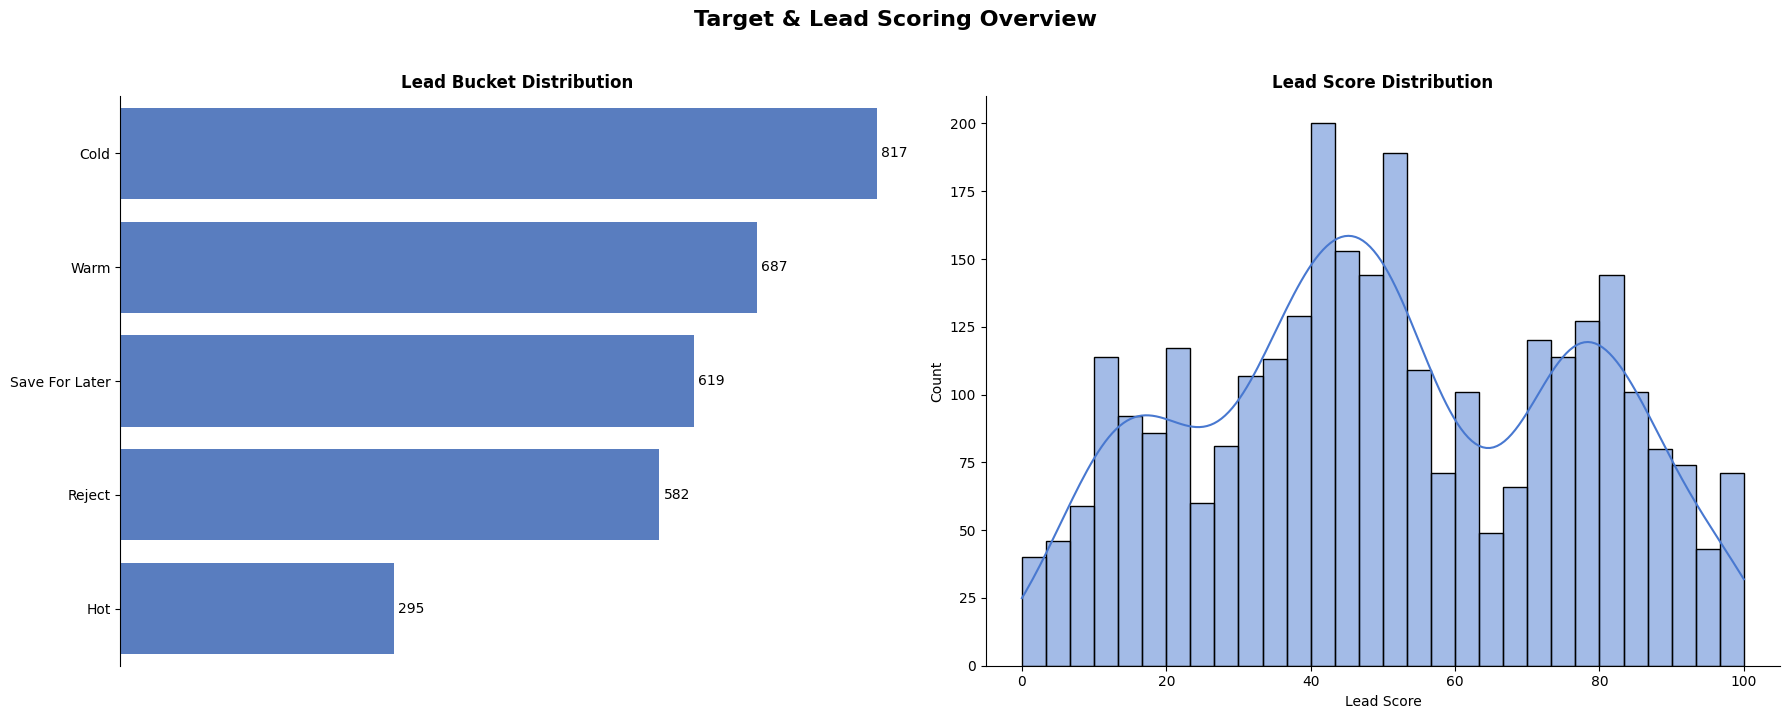

In [8]:
# setting up the plot
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (18, 7))
fig.suptitle("Target & Lead Scoring Overview", fontsize = 16, fontweight = "bold", y = 1.02)


# plot 01: distribution of the target variable "lead_bucket"
sns.countplot(
    data = df,
    y = "lead_bucket",
    order = df["lead_bucket"].value_counts().index,
    ax = axes[0]
)

axes[0].set_title("Lead Bucket Distribution", fontsize = 12, fontweight = "bold")
axes[0].set_ylabel("")

# adding value labels to each bar
for ax in [axes[0]]:
    for container in ax.containers:
        ax.bar_label(container = container, label_type = "edge", fontsize = 10, padding = 3)


# plot 02: distribution of "lead_score"
sns.histplot(
    data = df,
    x = "lead_score",
    bins = 30,
    kde = True,
    ax = axes[1]
)

axes[1].set_title("Lead Score Distribution", fontsize = 12, fontweight = "bold")
axes[1].set_xlabel("Lead Score")
axes[1].set_ylabel("Count")


# customizing the plot aesthetics
axes[0].xaxis.set_visible(False)
sns.despine(ax = axes[0], bottom = True)
sns.despine(ax = axes[1])
plt.tight_layout()
plt.show()

## Geography & Feasibility

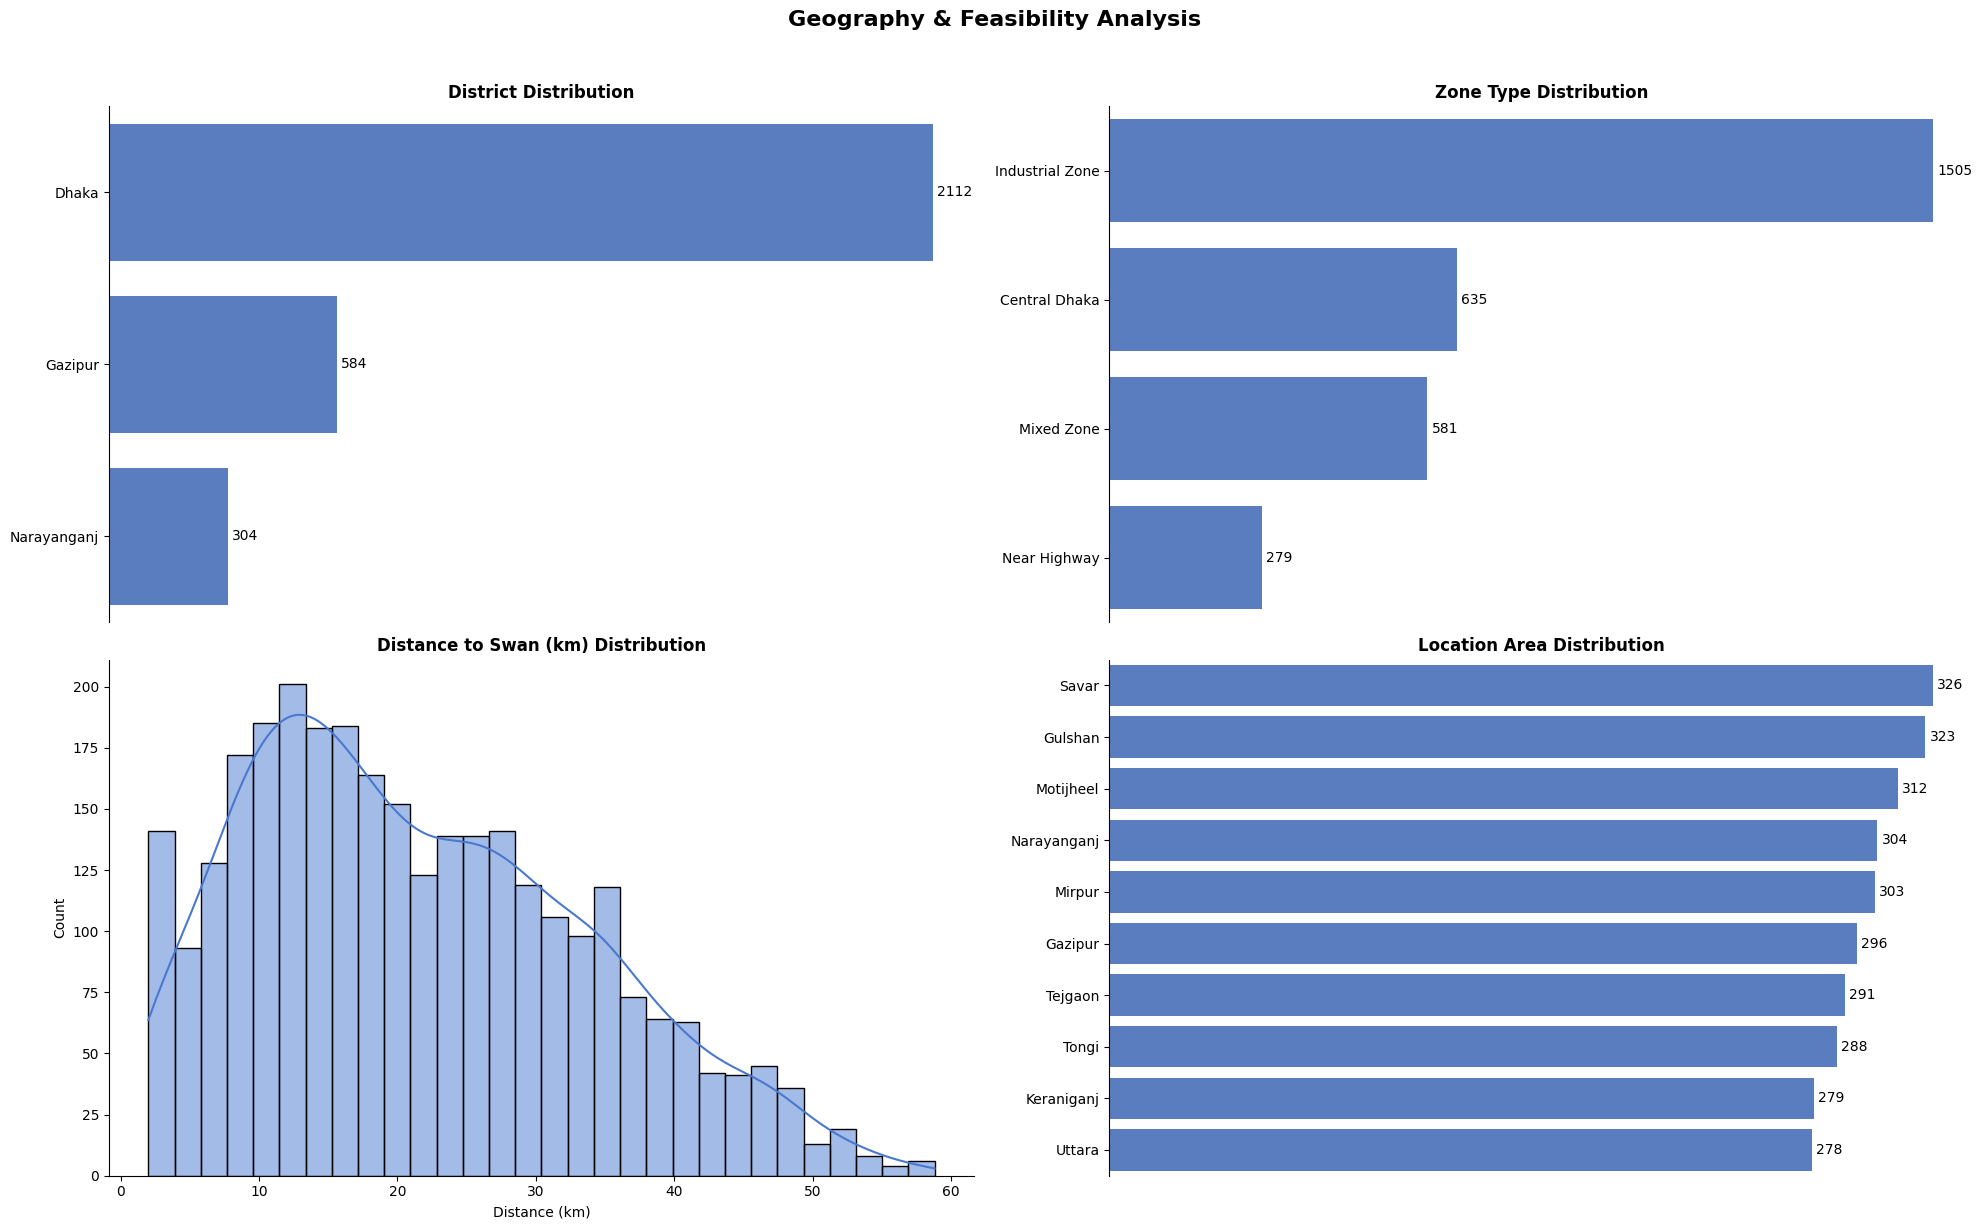

In [9]:
# setting up the plot
fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize = (20, 12))
fig.suptitle("Geography & Feasibility Analysis", fontsize = 16, fontweight = "bold", y = 1.02)


# plot 01: top 10 "district"
sns.countplot(
    data = df,
    y = "district",
    order = df["district"].value_counts().nlargest(10).index,
    ax = axes[0, 0]
)

axes[0, 0].set_title("District Distribution", fontsize = 12, fontweight = "bold")
axes[0, 0].set_ylabel("")


# plot 02: distribution of "zone_type"
sns.countplot(
    data = df,
    y = "zone_type",
    order = df["zone_type"].value_counts().index,
    ax = axes[0, 1]
)

axes[0, 1].set_title("Zone Type Distribution", fontsize = 12, fontweight = "bold")
axes[0, 1].set_ylabel("")


# plot 03: distribution of "distance_km"
sns.histplot(
    data = df,
    x = "distance_km",
    bins = 30,
    kde = True,
    ax = axes[1, 0]
)

axes[1, 0].set_title("Distance to Swan (km) Distribution", fontsize = 12, fontweight = "bold")
axes[1, 0].set_xlabel("Distance (km)")
axes[1, 0].set_ylabel("Count")


# plot 04: top 10 "location_area"
sns.countplot(
    data = df,
    y = "location_area",
    order = df["location_area"].value_counts().index,
    ax = axes[1, 1]
)

axes[1, 1].set_title("Location Area Distribution", fontsize = 12, fontweight = "bold")
axes[1, 1].set_ylabel("")


# adding value labels to each bar
for ax in [axes[0, 0], axes[0, 1], axes[1, 1]]:
    for container in ax.containers:
        ax.bar_label(container = container, label_type = "edge", fontsize = 10, padding = 3)


# customizing the plot aesthetics
for ax in [axes[0, 0], axes[0, 1], axes[1, 1]]:
    ax.xaxis.set_visible(False)
    sns.despine(ax = ax, bottom = True)
sns.despine(ax = axes[1, 0])
plt.tight_layout()
plt.show()

## Business Identity

In [10]:
# checking which columns has "0" entries and how many of them are there
(df == 0).sum()

company_name                        0
industry_category                   0
sub_industry                        0
location_area                       0
district                            0
zone_type                           0
distance_km                         0
company_type                        0
employee_estimate                   0
materials_used                      0
adhesive_type_needed                0
product_needed                      0
application_type                    0
purchase_stage                      0
expected_monthly_volume_liters    382
order_frequency                     0
urgency_days                        0
payment_terms_expected              0
has_google_listing                  0
google_review_count               381
has_phone                           0
credibility_level                   0
lead_source                         0
lead_bucket                         0
lead_score                         20
dtype: int64

<div style = "text-align: justify;">

Since there are **382** entries where the monthly expected volume are 0 liters and **381** entries where the google review count is also 0, we can assume that these are either new companies or companies that have not yet engaged with Swan Chemical Ltd. For simplicity, we will assume that these information were likely not provided.

</div>

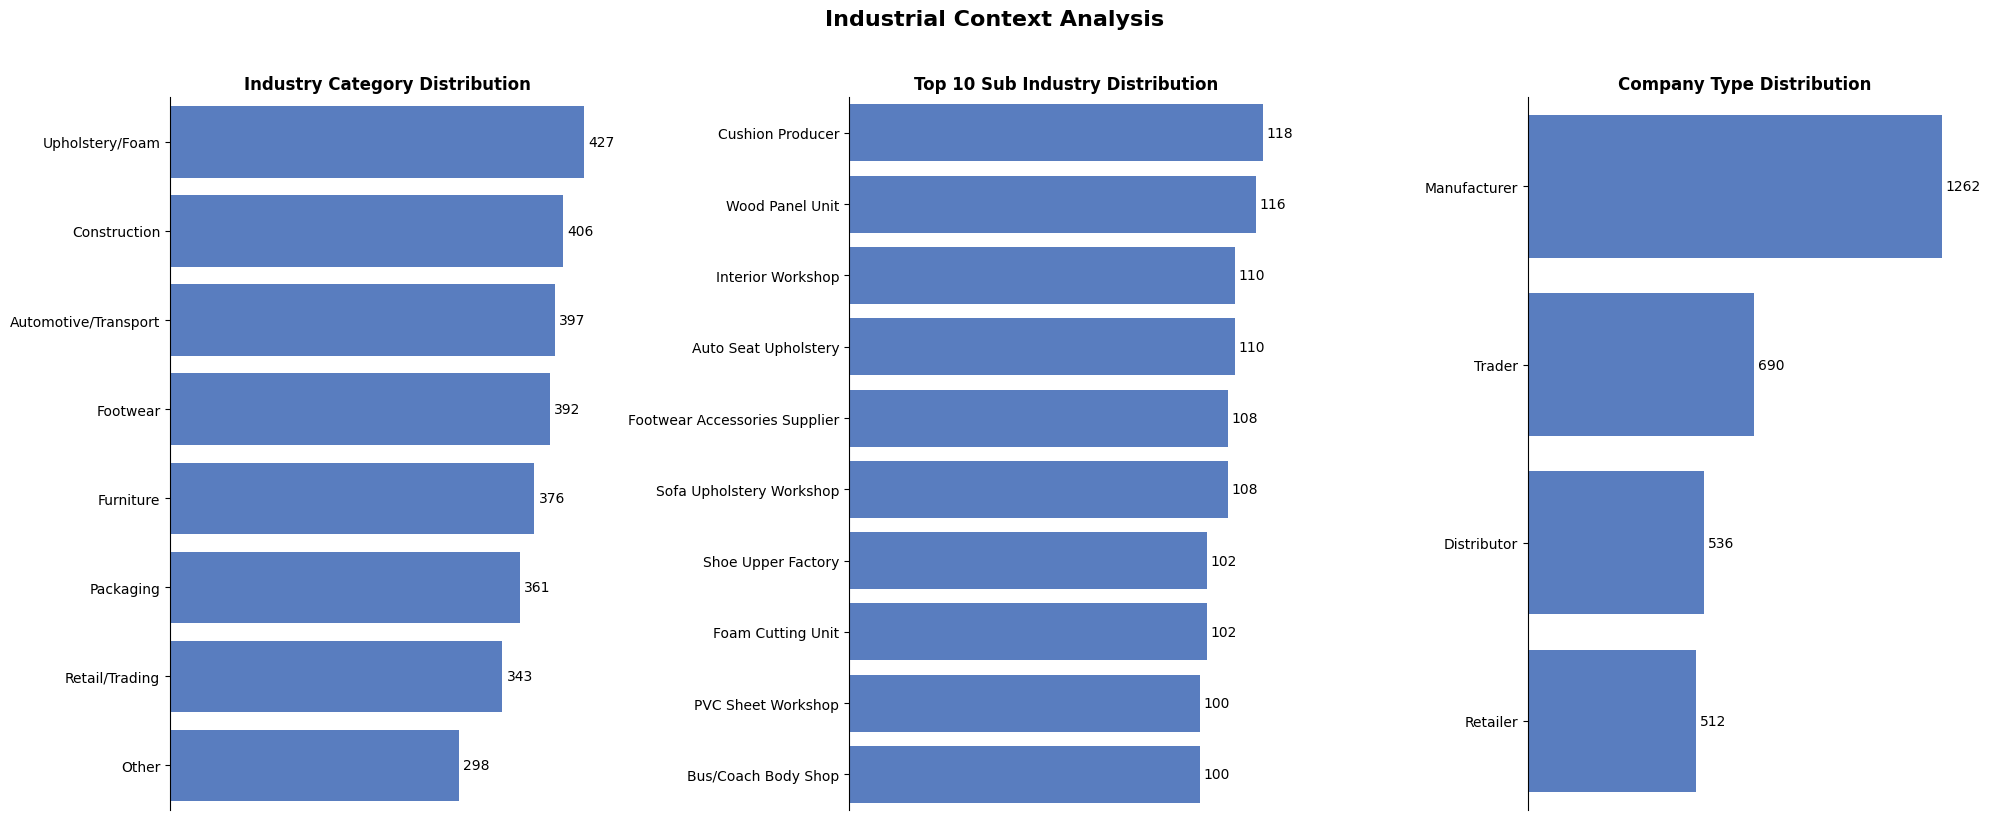

In [11]:
# setting up the plot
fig, axes = plt.subplots(nrows = 1, ncols = 3, figsize = (20, 8))
fig.suptitle("Industrial Context Analysis", fontsize = 16, fontweight = "bold", y = 1.02)


# plot 01: visualizing the distribution of the target variable "industry_category"
sns.countplot(
    data = df,
    y = "industry_category",
    order = df["industry_category"].value_counts().index,
    ax = axes[0]
)

axes[0].set_title("Industry Category Distribution", fontsize = 12, fontweight = "bold")
axes[0].set_ylabel("")


# plot 02: visualizing the top ten "sub_industry"
sns.countplot(
    data = df,
    y = "sub_industry",
    order = df["sub_industry"].value_counts().nlargest(10).index,
    ax = axes[1]
)

axes[1].set_title("Top 10 Sub Industry Distribution", fontsize = 12, fontweight = "bold")
axes[1].set_ylabel("")


# plot 03: visualizing the distribution of "company_type"
sns.countplot(
    data = df,
    y = "company_type",
    order = df["company_type"].value_counts().index,
    ax = axes[2]
)

axes[2].set_title("Company Type Distribution", fontsize = 12, fontweight = "bold")
axes[2].set_ylabel("")


# adding value labels to each bar
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container = container, label_type = "edge", fontsize = 10, padding = 3)


# customizing the plot aesthetics
for ax in axes:
    ax.xaxis.set_visible(False)
sns.despine(bottom = True)
plt.tight_layout()
plt.show()

## Capacity & Credibility

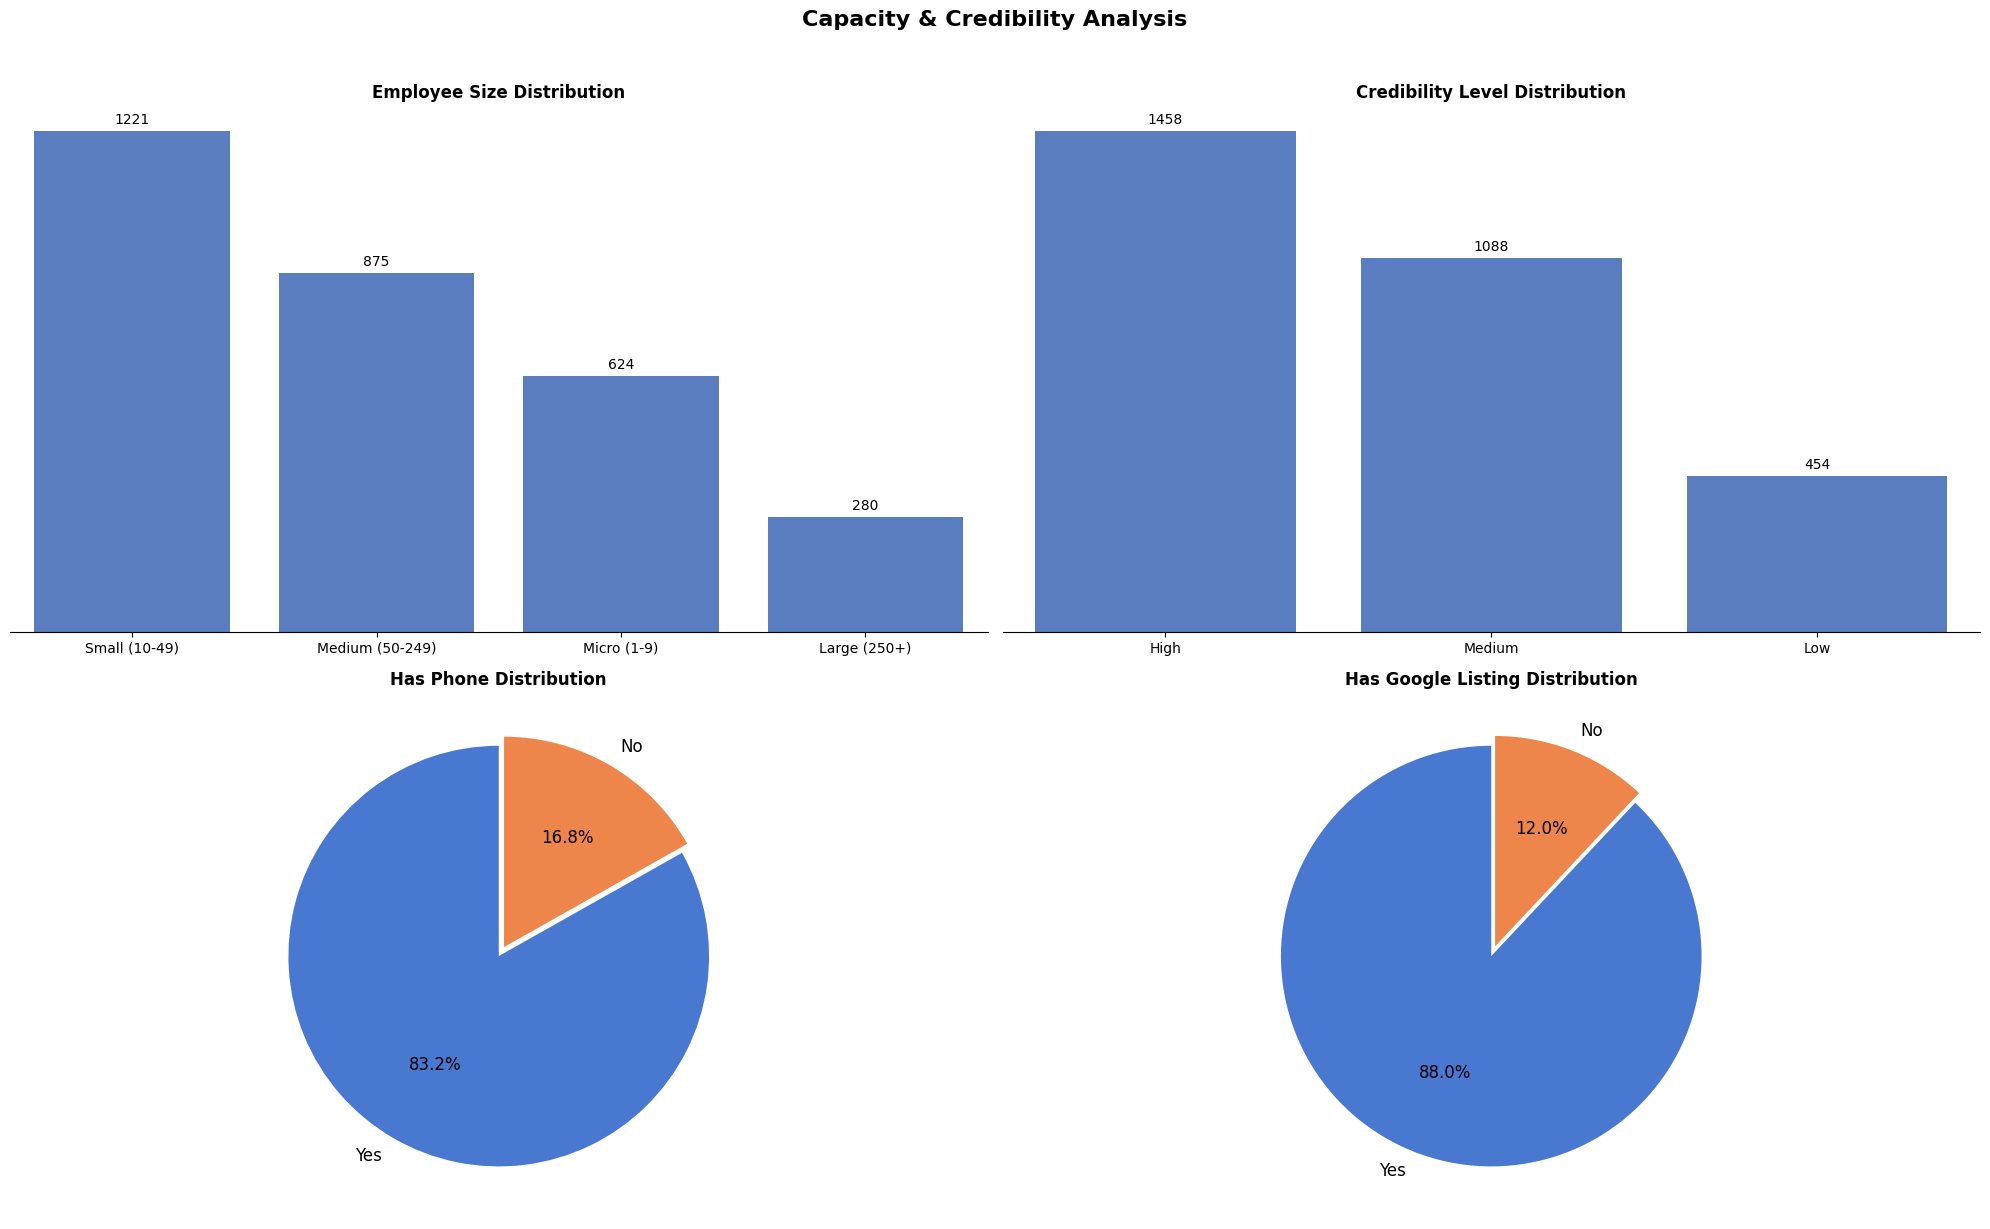

In [12]:
# setting up the plot
fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize = (20, 12))
fig.suptitle("Capacity & Credibility Analysis", fontsize = 16, fontweight = "bold", y = 1.02)


# plot 01: distribution of "employee_estimate"
sns.countplot(
    data = df,
    x = "employee_estimate",
    order = df["employee_estimate"].value_counts().index,
    ax = axes[0, 0]
)

axes[0, 0].set_title("Employee Size Distribution", fontsize = 12, fontweight = "bold")
axes[0, 0].set_xlabel("")


# plot 02: distribution of "credibility_level"
sns.countplot(
    data = df,
    x = "credibility_level",
    order = df["credibility_level"].value_counts().index,
    ax = axes[0, 1]
)

axes[0, 1].set_title("Credibility Level Distribution", fontsize = 12, fontweight = "bold")
axes[0, 1].set_xlabel("")


# plot 03: distribution of "has_phone"
phone_counts = df["has_phone"].value_counts()
axes[1, 0].pie(
    x = phone_counts.values,
    labels = phone_counts.index,
    autopct = "%1.1f%%",
    startangle = 90,
    explode = (0, 0.05),
    textprops = {"fontsize": 12}
)

axes[1, 0].set_title("Has Phone Distribution", fontsize = 12, fontweight = "bold")


# plot 04: distribution of "has_google_listing" (pie chart)
google_counts = df["has_google_listing"].value_counts()
axes[1, 1].pie(
    x = google_counts.values,
    labels = google_counts.index,
    autopct = "%1.1f%%",
    startangle = 90,
    textprops = {"fontsize": 12},
    explode = (0, 0.05)
)
axes[1, 1].set_title("Has Google Listing Distribution", fontsize = 12, fontweight = "bold")


# adding value labels to each bar
for ax in [axes[0, 0], axes[0, 1]]:
    for container in ax.containers:
        ax.bar_label(container = container, label_type = "edge", fontsize = 10, padding = 3)


# customizing the plot aesthetics
for ax in [axes[0, 0], axes[0, 1]]:
    ax.yaxis.set_visible(False)
sns.despine(left = True)
plt.tight_layout()
plt.show()

## Digital Signal

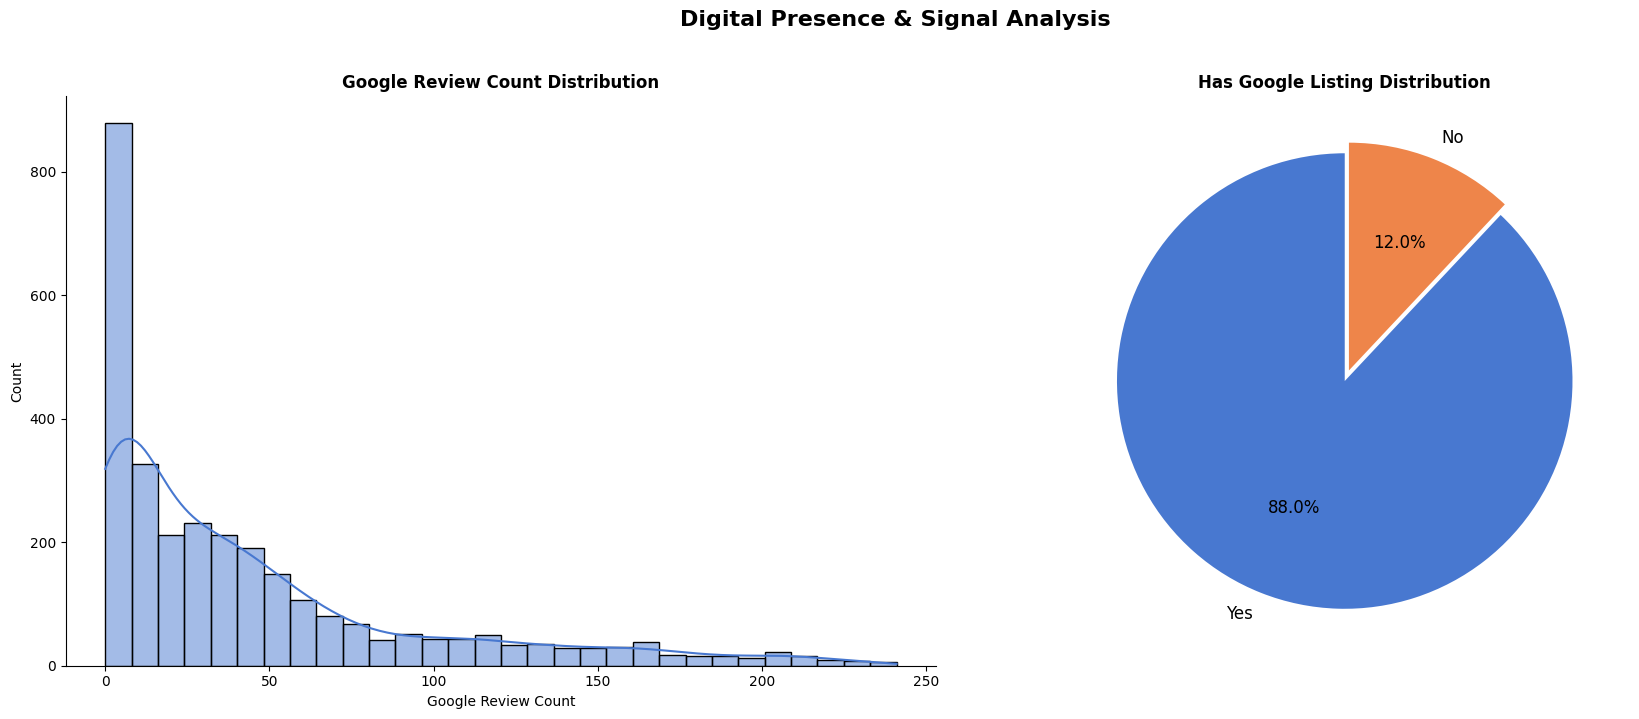

In [13]:
# setting up the plot
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (18, 7))
fig.suptitle("Digital Presence & Signal Analysis", fontsize = 16, fontweight = "bold", y = 1.02)


# plot 01: distribution of "google_review_count"
sns.histplot(
    data = df,
    x = "google_review_count",
    bins = 30,
    kde = True,
    ax = axes[0]
)

axes[0].set_title("Google Review Count Distribution", fontsize = 12, fontweight = "bold")
axes[0].set_xlabel("Google Review Count")
axes[0].set_ylabel("Count")


# plot 02: distribution of "has_google_listing"
google_counts = df["has_google_listing"].value_counts()
axes[1].pie(
    x = google_counts.values,
    labels = google_counts.index,
    autopct = "%1.1f%%",
    startangle = 90,
    textprops = {"fontsize": 12},
    explode = (0, 0.05)
)

axes[1].set_title("Has Google Listing Distribution", fontsize = 12, fontweight = "bold")


# adding value labels to each bar
for container in axes[1].containers:
    axes[1].bar_label(container = container, label_type = "edge", fontsize = 10, padding = 3)


# customizing the plot aesthetics
axes[1].xaxis.set_visible(False)
sns.despine()
plt.tight_layout()
plt.show()

## Need & Product Fit

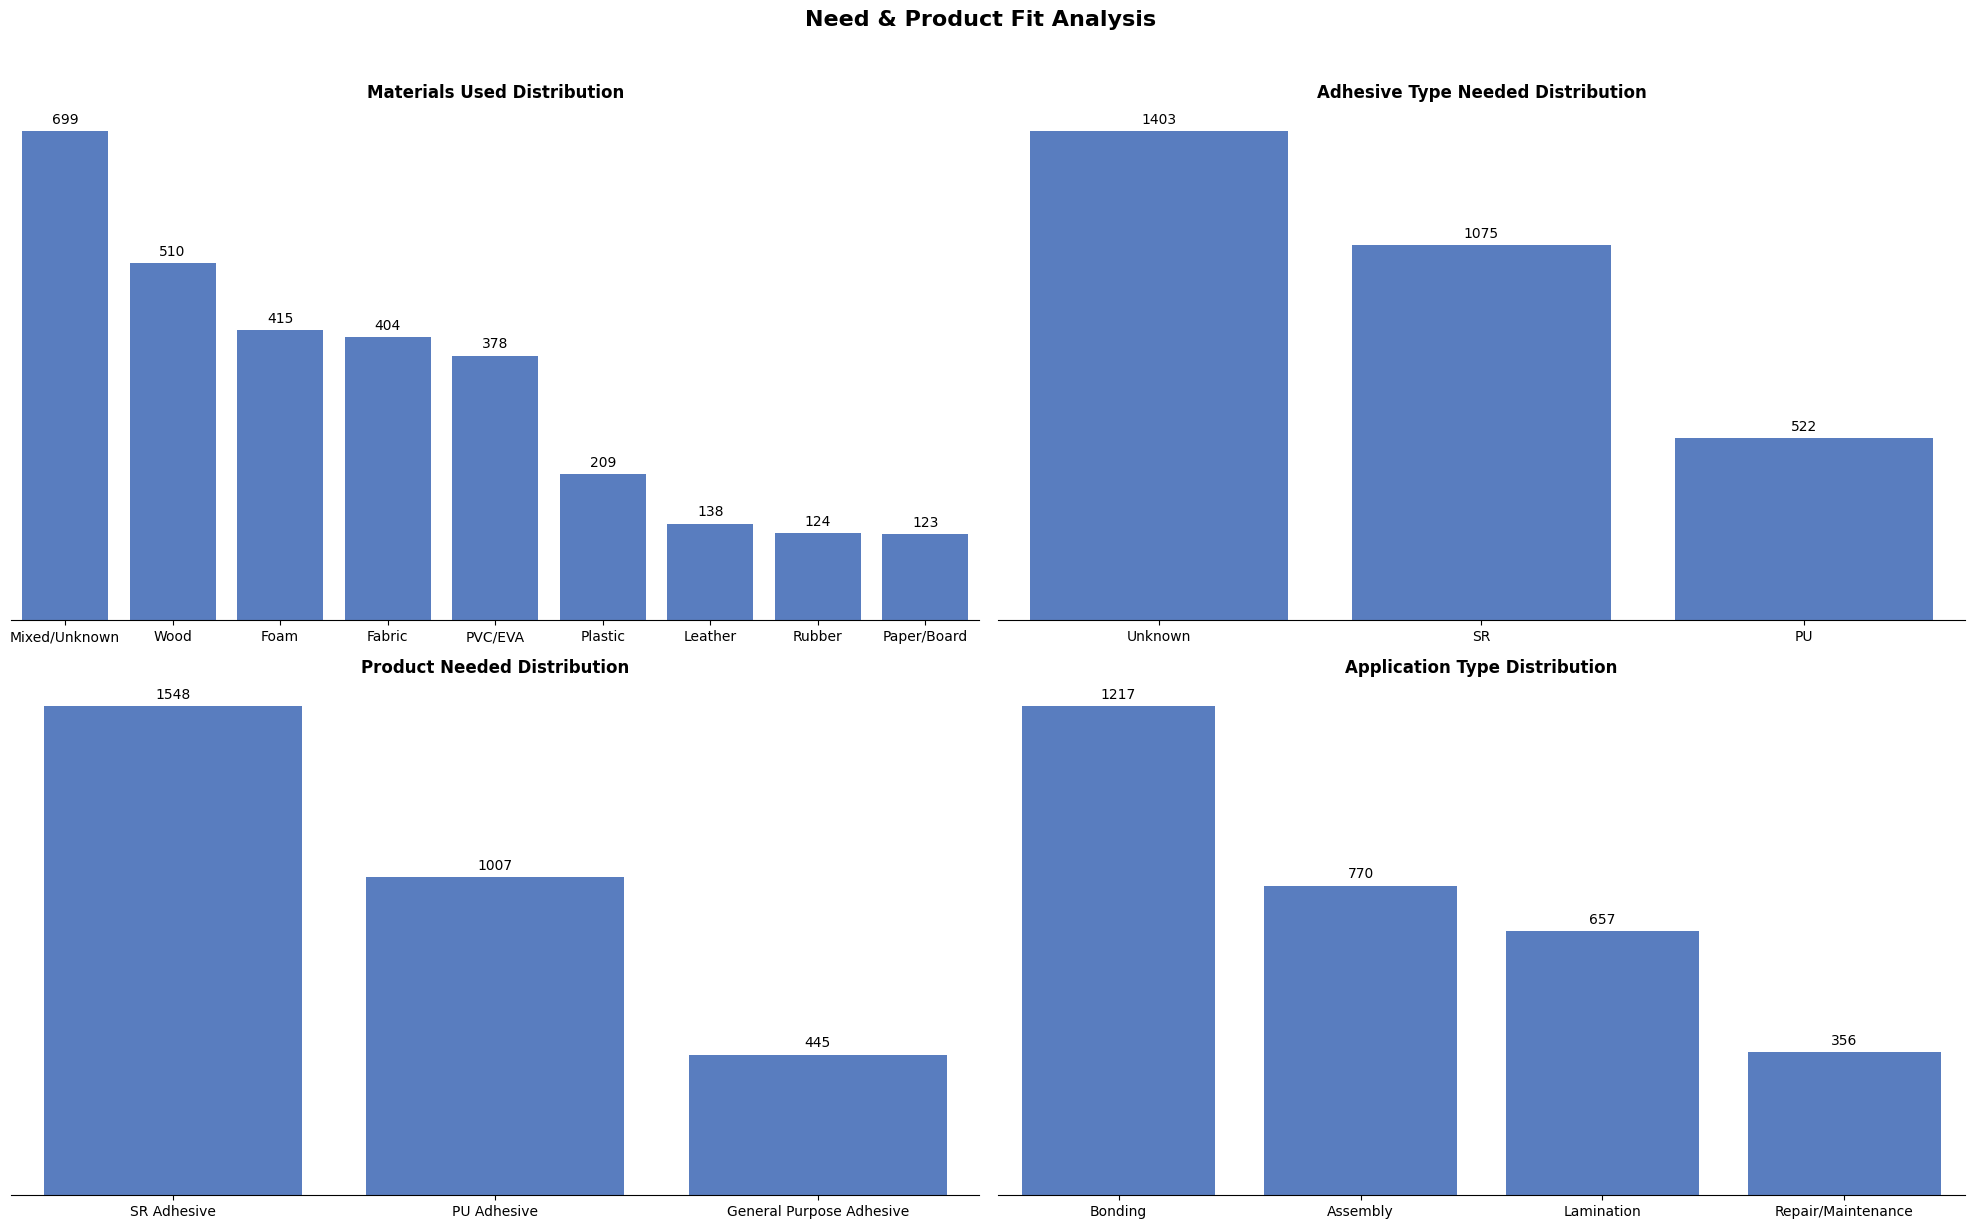

In [14]:
# setting up the plot
fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize = (20, 12))
fig.suptitle("Need & Product Fit Analysis", fontsize = 16, fontweight = "bold", y = 1.02)


# plot 01: distribution of "materials_used"
sns.countplot(
    data = df,
    x = "materials_used",
    order = df["materials_used"].value_counts().index,
    ax = axes[0, 0]
)

axes[0, 0].set_title("Materials Used Distribution", fontsize = 12, fontweight = "bold")
axes[0, 0].set_xlabel("")


# plot 02: distribution of "adhesive_type_needed"
sns.countplot(
    data = df,
    x = "adhesive_type_needed",
    order = df["adhesive_type_needed"].value_counts().index,
    ax = axes[0, 1]
)

axes[0, 1].set_title("Adhesive Type Needed Distribution", fontsize = 12, fontweight = "bold")
axes[0, 1].set_xlabel("")


# plot 03: distribution of "product_needed"
sns.countplot(
    data = df,
    x = "product_needed",
    order = df["product_needed"].value_counts().index,
    ax = axes[1, 0]
)

axes[1, 0].set_title("Product Needed Distribution", fontsize = 12, fontweight = "bold")
axes[1, 0].set_xlabel("")


# plot 04: distribution of "application_type"
sns.countplot(
    data = df,
    x = "application_type",
    order = df["application_type"].value_counts().index,
    ax = axes[1, 1]
)

axes[1, 1].set_title("Application Type Distribution", fontsize = 12, fontweight = "bold")
axes[1, 1].set_xlabel("")


# adding value labels to each bar
for ax in axes.ravel():
    for container in ax.containers:
        ax.bar_label(container = container, label_type = "edge", fontsize = 10, padding = 3)


# customizing the plot aesthetics
for ax in axes.ravel():
    ax.yaxis.set_visible(False)
sns.despine(left = True)
plt.tight_layout()
plt.show()

## Purchase Behavior & Urgency

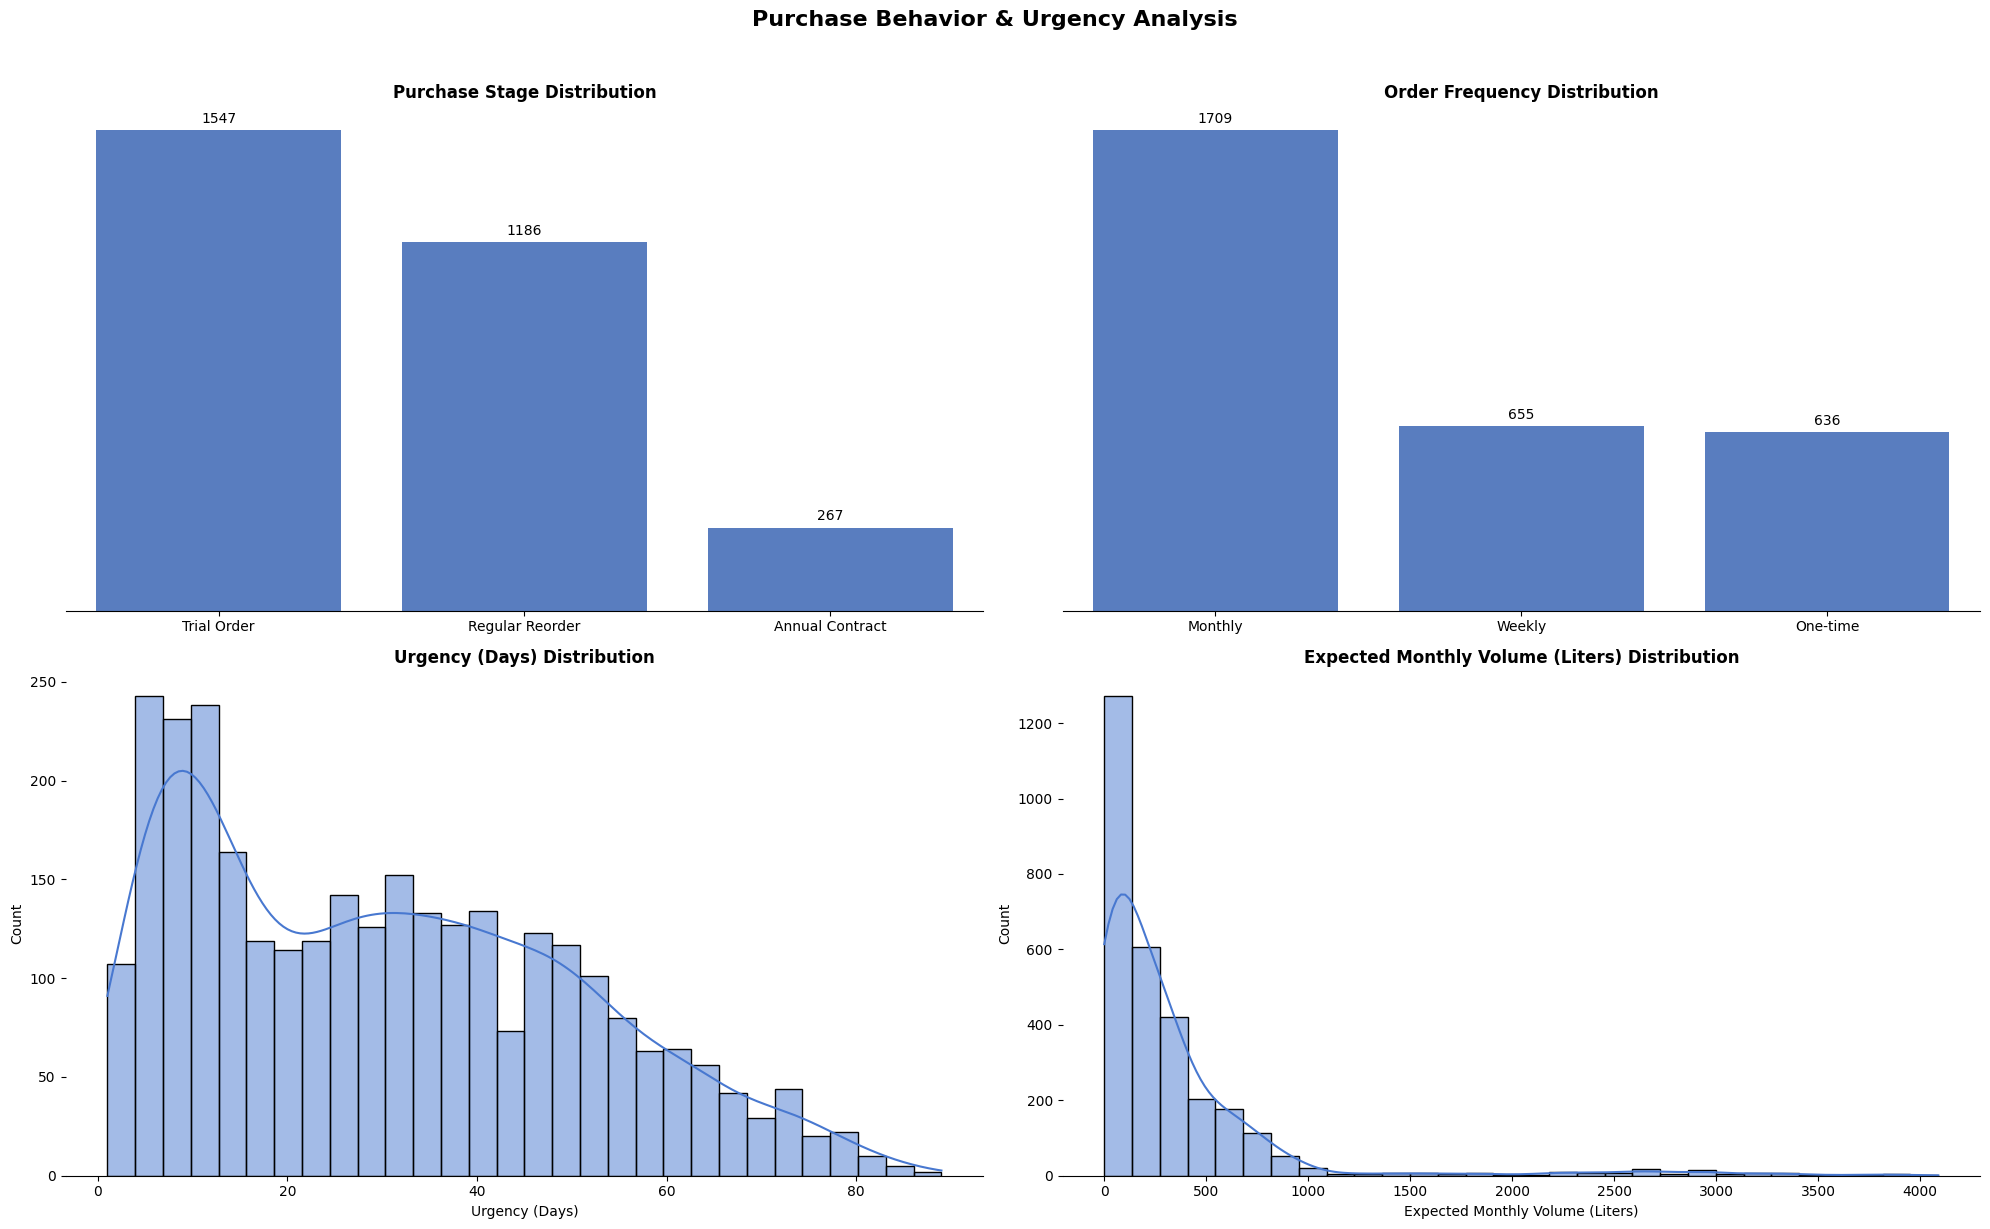

In [15]:
# setting up the plot
fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize = (20, 12))
fig.suptitle("Purchase Behavior & Urgency Analysis", fontsize = 16, fontweight = "bold", y = 1.02)


# plot 01: distribution of "purchase_stage"
sns.countplot(
    data = df,
    x = "purchase_stage",
    order = df["purchase_stage"].value_counts().index,
    ax = axes[0, 0]
)

axes[0, 0].set_title("Purchase Stage Distribution", fontsize = 12, fontweight = "bold")
axes[0, 0].set_xlabel("")


# plot 02: distribution of "order_frequency"
sns.countplot(
    data = df,
    x = "order_frequency",
    order = df["order_frequency"].value_counts().index,
    ax = axes[0, 1]
)

axes[0, 1].set_title("Order Frequency Distribution", fontsize = 12, fontweight = "bold")
axes[0, 1].set_xlabel("")


# plot 03: distribution of "urgency_days"
sns.histplot(
    data = df,
    x = "urgency_days",
    bins = 30,
    kde = True,
    ax = axes[1, 0]
)

axes[1, 0].set_title("Urgency (Days) Distribution", fontsize = 12, fontweight = "bold")
axes[1, 0].set_xlabel("Urgency (Days)")
axes[1, 0].set_ylabel("Count")


# plot 04: distribution of "expected_monthly_volume_liters"
sns.histplot(
    data = df,
    x = "expected_monthly_volume_liters",
    bins = 30,
    kde = True,
    ax = axes[1, 1]
)

axes[1, 1].set_title("Expected Monthly Volume (Liters) Distribution", fontsize = 12, fontweight = "bold")
axes[1, 1].set_xlabel("Expected Monthly Volume (Liters)")
axes[1, 1].set_ylabel("Count")


# adding value labels to each bar
for ax in [axes[0, 0], axes[0, 1]]:
    for container in ax.containers:
        ax.bar_label(container = container, label_type = "edge", fontsize = 10, padding = 3)


# customizing the plot aesthetics
for ax in [axes[0, 0], axes[0, 1]]:
    ax.yaxis.set_visible(False)
sns.despine(left = True)
plt.tight_layout()
plt.show()

## Commercial Term & Source

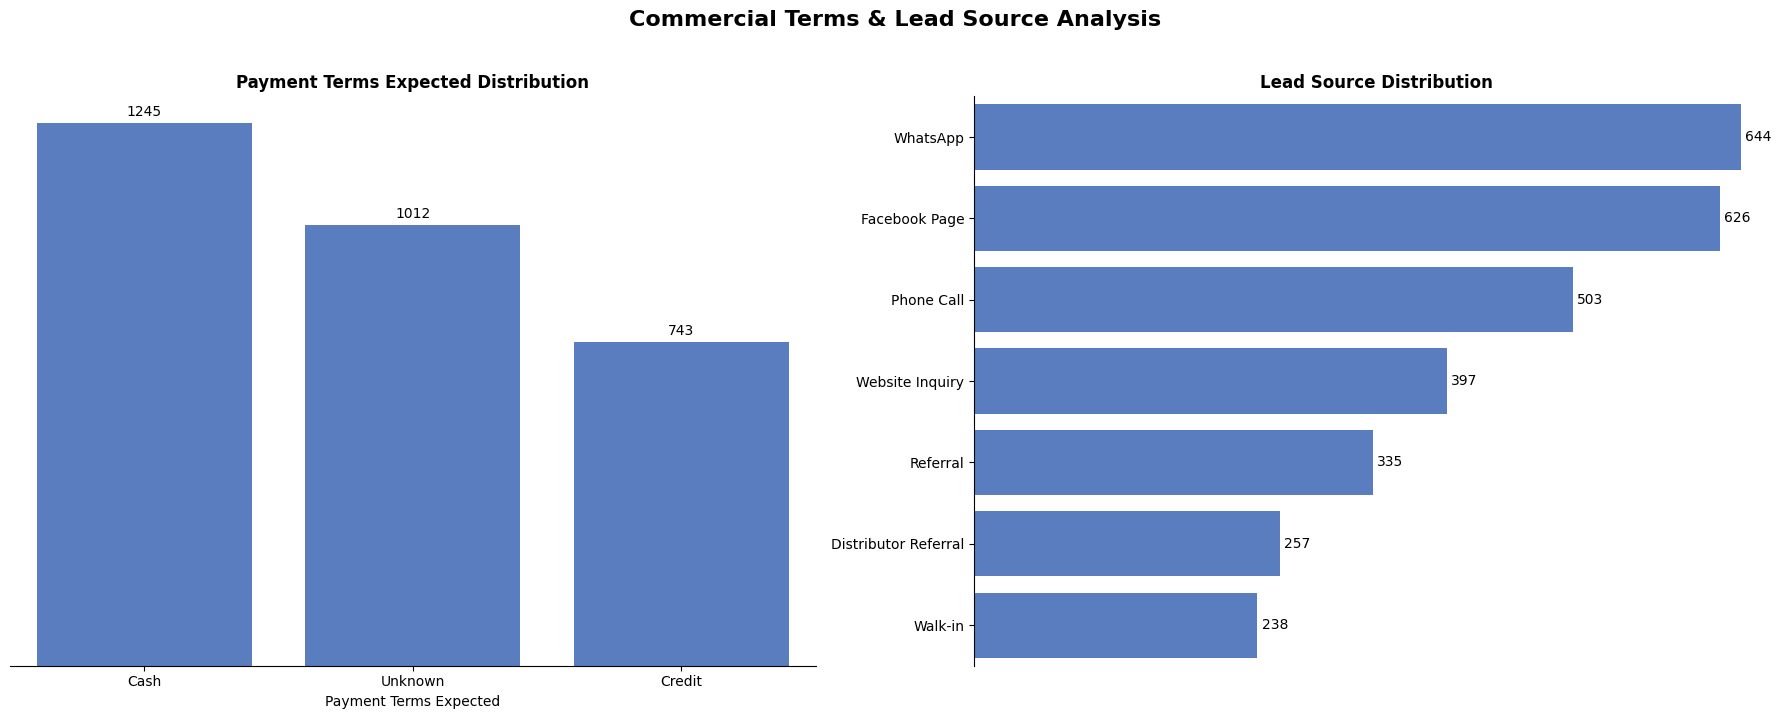

In [16]:
# setting up the plot
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (18, 7))
fig.suptitle("Commercial Terms & Lead Source Analysis", fontsize = 16, fontweight = "bold", y = 1.02)


# plot 01: distribution of "payment_terms_expected"
sns.countplot(
    data = df,
    x = "payment_terms_expected",
    order = df["payment_terms_expected"].value_counts().index,
    ax = axes[0]
)

axes[0].set_title("Payment Terms Expected Distribution", fontsize = 12, fontweight = "bold")
axes[0].set_xlabel("Payment Terms Expected")


# plot 02: distribution of "lead_source"
sns.countplot(
    data = df,
    y = "lead_source",
    order = df["lead_source"].value_counts().index,
    ax = axes[1]
)

axes[1].set_title("Lead Source Distribution", fontsize = 12, fontweight = "bold")
axes[1].set_ylabel("")


# adding value labels to each bar
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container = container, label_type = "edge", fontsize = 10, padding = 3)


# customizing the plot aesthetics
axes[0].yaxis.set_visible(False)
axes[1].xaxis.set_visible(False)
sns.despine(ax = axes[0], left = True)
sns.despine(ax = axes[1], bottom = True)
plt.tight_layout()
plt.show()

## Numerical Features

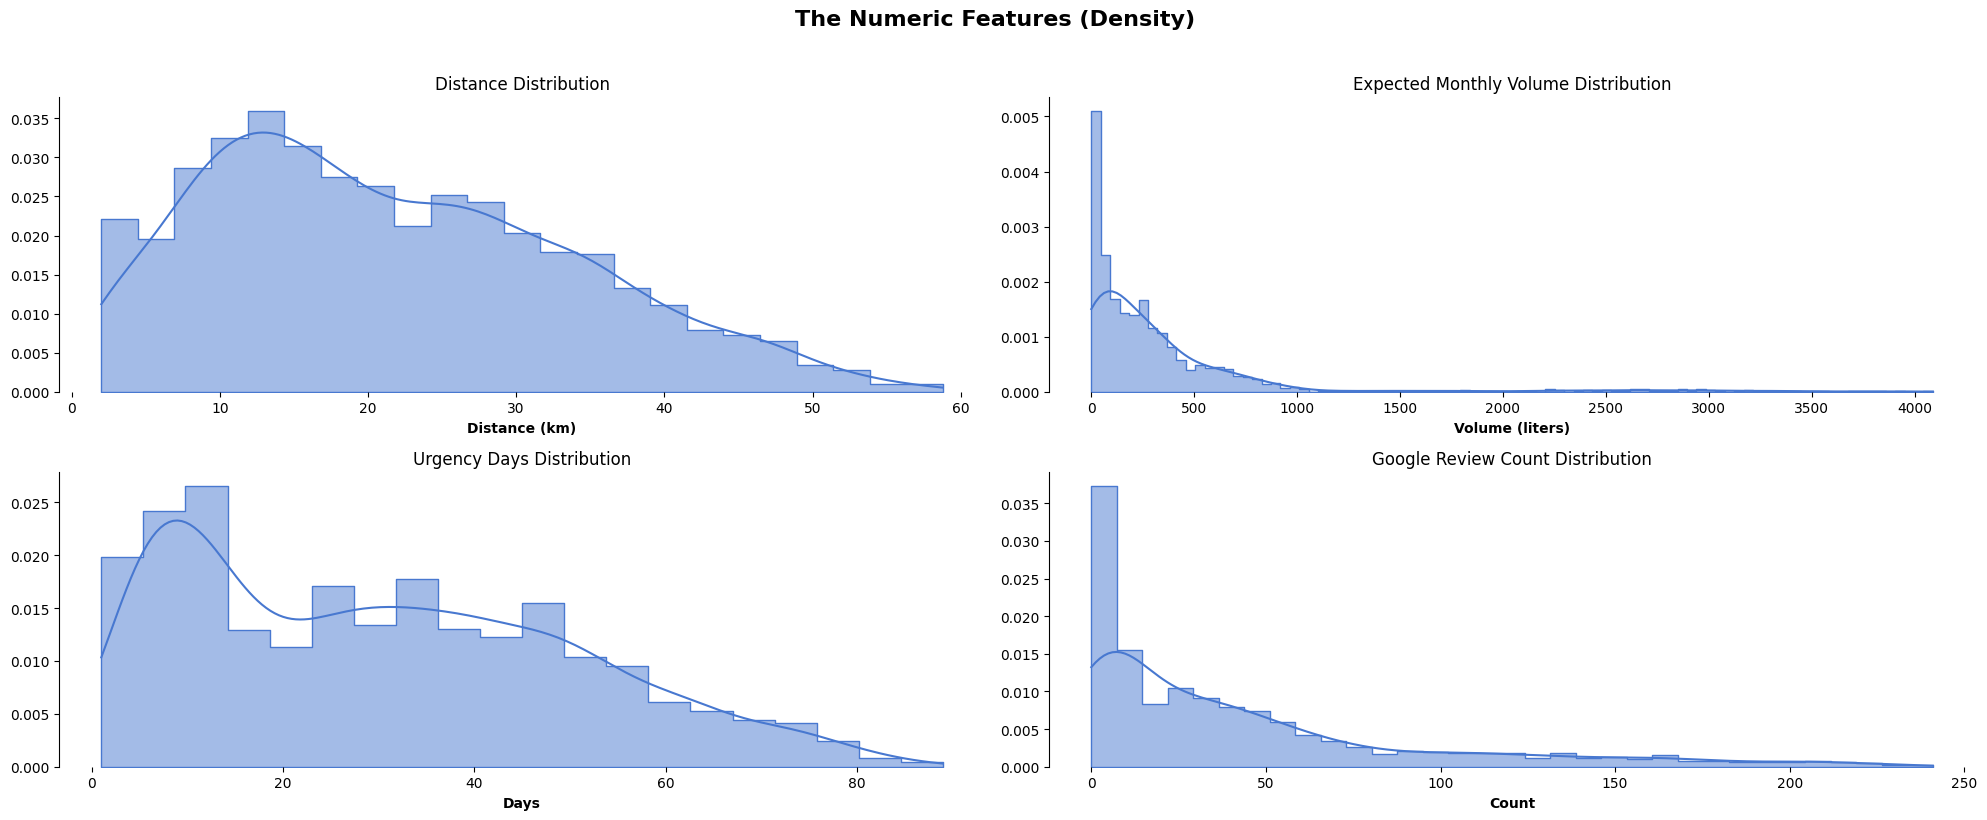

In [17]:
# setting up the plot
fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize = (20, 8))
fig.suptitle("The Numeric Features (Density)", fontsize = 16, fontweight = "bold", y = 1.02)

# plot 01: visualizing the distribution of the target variable "industry_category"
sns.histplot(data = df["distance_km"], kde = True, element = "step", stat = "density", ax = axes[0, 0])

axes[0, 0].set_title("Distance Distribution", fontsize = 12)
axes[0, 0].set_xlabel("Distance (km)", fontweight = "bold")
axes[0, 0].set_ylabel("")


# plot 02: visualizing the top ten "sub_industry"
sns.histplot(data = df["expected_monthly_volume_liters"], kde = True, element = "step", stat = "density", ax = axes[0, 1])

axes[0, 1].set_title("Expected Monthly Volume Distribution", fontsize = 12)
axes[0, 1].set_xlabel("Volume (liters)", fontweight = "bold")
axes[0, 1].set_ylabel("")

# plot 03: visualizing the distribution of "company_type"
sns.histplot(data = df["urgency_days"], kde = True, element = "step", stat = "density", ax = axes[1, 0])

axes[1, 0].set_title("Urgency Days Distribution", fontsize = 12)
axes[1, 0].set_xlabel("Days", fontweight = "bold")
axes[1, 0].set_ylabel("")

# plot 04: visualizing the distribution of "company_type"
sns.histplot(data = df["google_review_count"], kde = True, element = "step", stat = "density", ax = axes[1, 1])

axes[1, 1].set_title("Google Review Count Distribution", fontsize = 12)
axes[1, 1].set_xlabel("Count", fontweight = "bold")
axes[1, 1].set_ylabel("")

# adding value labels to each bar
for ax in axes.flat:
    for container in ax.containers:
        ax.bar_label(container = container, label_type = "edge", fontsize = 10, padding = 3)

# customizing the plot aesthetics
sns.despine(bottom = True)
plt.tight_layout()
plt.show()

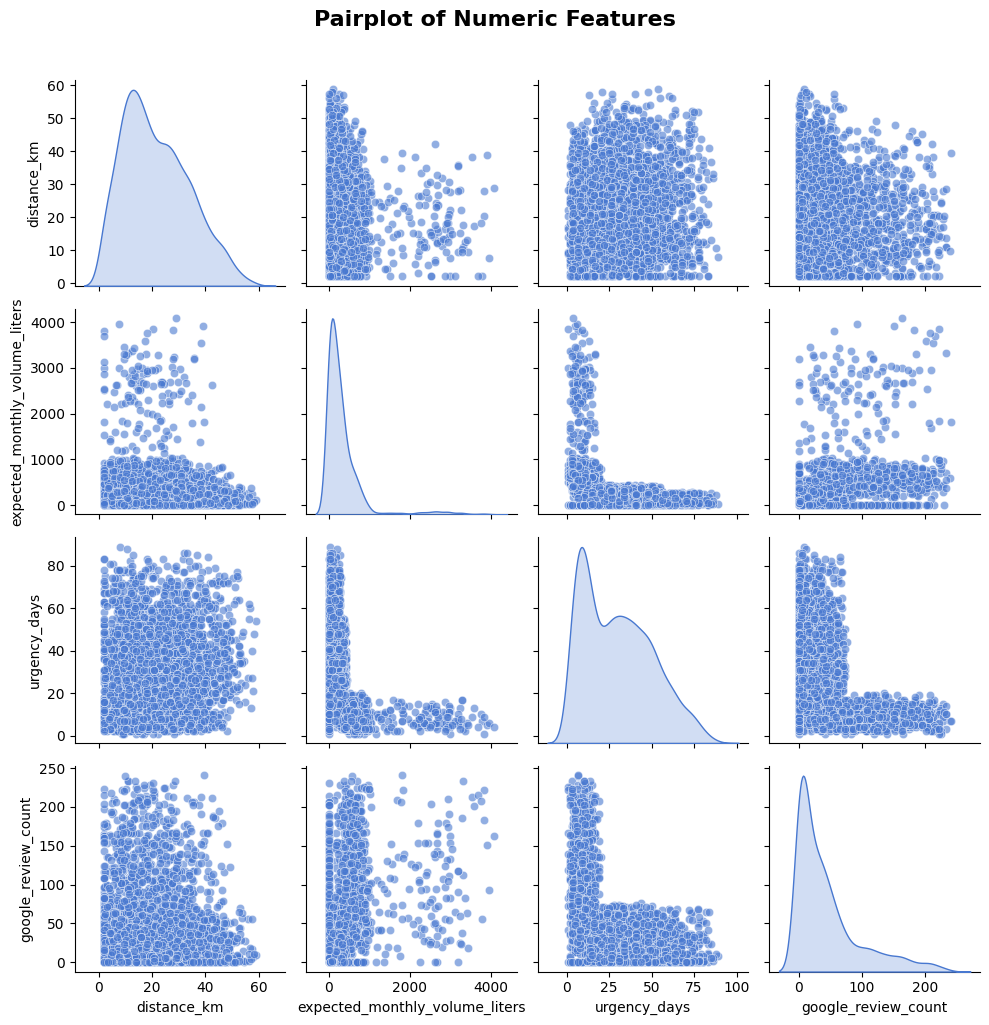

In [18]:
# creating a pairplot to visualize the relationships between the numeric features
sns.pairplot(
    data = df,
    vars = ["distance_km", "expected_monthly_volume_liters", "urgency_days", "google_review_count",
],
    diag_kind = "kde",
    plot_kws = {"alpha": 0.6}
)

# Customizing the plot
plt.suptitle("Pairplot of Numeric Features", fontsize = 16, fontweight = "bold", y = 1.02)
plt.tight_layout()
plt.show()

# **Machine Learning**

## Data Preparation

<div style="text-align: justify;">

First, we split the dataset into features (X) and target (y). The target variable is the lead bucket classification, which we will predict using various machine learning models. We also perform a train-test split to evaluate our models on unseen data.

</div>

In [19]:
# deciding x and y
y = df["lead_bucket"]
X = df.drop(columns = ["company_name", "lead_bucket", "lead_score"])

In [20]:
# conducting the train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = SEED, stratify = y)

<div style = "text-align: justify;">

### **Preprocessing Pipeline**

The features fall into three groups, and each group gets its own preprocessing: **ordinal** columns (ordered categories) are ordinal-encoded, **nominal** columns are one-hot encoded, and the **numeric** columns are standardised (only for Logistic Regression, since tree-based models are unaffected by feature scale).

* **Ordinal Encoding:** Converts categorical values with a meaningful order into integers. It is used for columns where the categories have a natural order or hierarchy.
* **One-hot encoding:** Converts nominal categorical variables (categories without an inherent order) into binary columns. It is used for features such as industry_category, district, and product_needed to represent each category without implying a numerical ranking.
* **StandardScaler:** Standardizes numerical features by subtracting the training-set mean and dividing by its standard deviation, resulting in a mean of approximately 0 and a standard deviation of 1. It is useful for scale-sensitive models, ensuring features with larger numerical ranges do not disproportionately influence the model.

Instead of transforming the data step by step, all of this is wrapped in a **ColumnTransformer** and chained with each model in a **Pipeline**. Every step is learned from the training data only, and during cross-validation it is re-learned inside each fold, so no information from a validation fold leaks into the preprocessing.

</div>

In [21]:
# numeric columns
numeric_cols = [
    "distance_km",
    "expected_monthly_volume_liters",
    "urgency_days",
    "google_review_count",
]

# ordinal columns
ordinal_cols = ["employee_estimate", "credibility_level", "purchase_stage"]

# one-hot columns
onehot_cols = [c for c in X.columns if c not in numeric_cols + ordinal_cols]

# extracting the category order of the ordinal columns (set earlier as ordered categoricals)
ordinal_categories = [X_train[col].cat.categories.tolist() for col in ordinal_cols]

# a function that builds a fresh preprocessor (so every model gets its own copy)
def build_preprocessor(scale_numeric):
    return ColumnTransformer(
        transformers = [
            ("ordinal", OrdinalEncoder(
                categories = ordinal_categories,
                handle_unknown = "use_encoded_value",
                unknown_value = -1
            ), ordinal_cols),
            ("onehot", OneHotEncoder(
                sparse_output = False,
                handle_unknown = "ignore",
                drop = "first"
            ), onehot_cols),
            ("numeric", StandardScaler() if scale_numeric else "passthrough", numeric_cols),
        ],
        remainder = "drop",
        verbose_feature_names_out = False    # keeps the original column names (e.g. has_phone_1)
    ).set_output(transform = "pandas")       # returns a DataFrame instead of a NumPy array

Let us run an inspection of the preprocessed data to ensure that the transformations have been applied correctly and that the data is ready for modeling.

In [22]:
# fitting the preprocessor on the training data only, just to inspect the output
preprocessor_check = build_preprocessor(scale_numeric = True).fit(X = X_train)
X_train_check = preprocessor_check.transform(X = X_train)

# checking the shape and missing values (expecting 89 features)
print(f"Features after preprocessing: {X_train_check.shape[1]}")
print(f"Missing values: {X_train_check.isna().sum().sum()}")
X_train_check.head()

Features after preprocessing: 89
Missing values: 0


,employee_estimate,credibility_level,purchase_stage,industry_category_Construction,industry_category_Footwear,industry_category_Furniture,industry_category_Other,industry_category_Packaging,industry_category_Retail/Trading,industry_category_Upholstery/Foam,...,lead_source_Facebook Page,lead_source_Phone Call,lead_source_Referral,lead_source_Walk-in,lead_source_Website Inquiry,lead_source_WhatsApp,distance_km,expected_monthly_volume_liters,urgency_days,google_review_count
2678,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,-0.219587,-0.639942,-0.206767,-0.869739
16,1.0,2.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.432869,-0.639942,-1.353625,1.287958
792,2.0,2.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.489254,1.181895,-1.004581,0.895650
998,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.125600,-0.482593,-0.107040,-0.791277
503,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.681397,-0.507238,1.588315,-0.732431


## Modeling

<div style = "text-align: justify;">

### **Multinomial Logistic Regression**

***Logistic Regression*** is a classification algorithm that, despite its name, predicts a *category* rather than a number. It first combines the features into a single score using a weighted sum ($z = w_1x_1 + w_2x_2 + \dots + b$) and then passes that score through the **sigmoid function**, which squeezes it into a probability between 0 and 1. In the simplest (binary) case, the model predicts one class when this probability is above 0.5. The weights are learned by minimizing the **log loss** (cross-entropy), which punishes confident wrong predictions heavily. Our target has **five** classes (Hot, Warm, Cold, Save For Later, Reject), so we need a version that handles more than two. ***Multinomial Logistic Regression*** (also called *softmax regression*) is that variant.

The five probabilities are always positive and add up to exactly 1, and all classes are learned together in a single model. The alternative, *One-vs-Rest* (OvR), trains five separate "this class vs everything else" models whose probabilities are independent of each other and do not add up to 1 unless they are rescaled afterwards.

In scikit-learn, `LogisticRegression` with the `lbfgs` solver uses this multinomial form automatically when there are more than two classes. Because it is linear, it cannot capture interactions on its own (e.g., high urgency *and* high volume), so we expect the tree-based models to do better later.

</div>

In [23]:
# creating the pipeline (scaling is needed only for Logistic Regression; lbfgs fits the multinomial/softmax version automatically for more than two classes))
log_pipe = Pipeline(
    steps = [
        ("preprocess", build_preprocessor(scale_numeric = True)),
        ("model", LogisticRegression(solver = "lbfgs", max_iter = 2000))
    ]
)

# fitting the pipeline (preprocessing is learned from the training data only)
log_pipe.fit(X = X_train, y = y_train)
log_model = log_pipe.named_steps["model"]
print(f"Iterations used: {log_model.n_iter_[0]} of 2000")

# predicting the target variable
y_pred_log = log_pipe.predict(X = X_test)
y_prob_log = log_pipe.predict_proba(X = X_test)

Iterations used: 149 of 2000


In [24]:
# calculating the evaluation metrics for the test dataset (macro F1 is the primary metric)
accuracy_log = accuracy_score(y_true = y_test, y_pred = y_pred_log)
f1_test_log = f1_score(y_true = y_test, y_pred = y_pred_log, average = "macro")

# generating the classification report for the test dataset
report_log = classification_report(y_true = y_test, y_pred = y_pred_log)

# printing a summary report
print(
f"""Model Performance Report for Multinomial Logistic Regression

Macro F1-Score: {f1_test_log:.3%}
Accuracy Score: {accuracy_log:.3%}

{report_log}"""
)

Model Performance Report for Multinomial Logistic Regression

Macro F1-Score: 71.526%
Accuracy Score: 73.222%

                precision    recall  f1-score   support

          Cold       0.71      0.72      0.71       245
           Hot       0.64      0.56      0.59        88
        Reject       0.78      0.90      0.84       175
Save For Later       0.73      0.60      0.66       186
          Warm       0.75      0.80      0.77       206

      accuracy                           0.73       900
     macro avg       0.72      0.72      0.72       900
  weighted avg       0.73      0.73      0.73       900



<div style = "text-align: justify;">

**Key Insights:**

* Multinomial Logistic Regression reaches **73.22% accuracy** with a **macro F1 of 0.72**, a solid baseline but clearly uneven across buckets (class F1 ranges from 0.59 to 0.84).
* It is strongest on **Reject** (recall 0.90, F1 0.84) and **Warm** (recall 0.80, F1 0.77), and weakest on **Hot** (recall 0.56, F1 0.59), meaning it misses a meaningful share of the highest-priority leads.
* **Save For Later** is also weak (recall 0.60, F1 0.66), while **Cold** is moderate (F1 0.71).

As this is a multiclass classification problem, we will use the One-vs-Rest (**OVR**) strategy to compute the ROC-AUC scores. **Three** of the approaches are:

1. **OVR Macro AUC:** Average one-vs-rest (OVR) ROC-AUC across all classes (each class gets equal weight); used to judge overall multiclass separability fairly, especially when classes are imbalanced.
2. **OVR Weighted AUC:** One-vs-rest ROC-AUC averaged across classes but weighted by how frequent each class is; used to summarize multiclass performance in a way that reflects the real class distribution.
3. **Qualified-vs-Not AUC:** ROC-AUC after collapsing buckets into “Qualified” (e.g., Hot + Warm) vs “Not Qualified” (others); used to evaluate the core business question: can we prioritize good leads above the rest?

</div>

In [25]:
# creating the confusion matrix (shown in the combined plot later)
matrix_log = confusion_matrix(y_true = y_test, y_pred = y_pred_log, labels = log_model.classes_)

# calculating the OVR ROC-AUC scores (each bucket vs the rest)
auc_macro_ovr_log = roc_auc_score(
    y_true = y_test,
    y_score = y_prob_log,
    multi_class = "ovr",
    average = "macro"
)
auc_weighted_ovr_log = roc_auc_score(
    y_true = y_test,
    y_score = y_prob_log,
    multi_class = "ovr",
    average = "weighted"
)

# converting the target to Qualified (Hot/Warm = 1) vs Not (everything else = 0); the same variable is reused for every model
qualified = ["Hot", "Warm"]
y_test_bin_auc = y_test.isin(qualified).astype(dtype = int)

# QualifiedScore = P(Hot) + P(Warm), using the class order of this model
qualified_idx_log = [list(log_model.classes_).index(c) for c in qualified]
p_qualified_log = y_prob_log[:, qualified_idx_log].sum(axis = 1)

# calculating the ROC curve (kept for the combined plot) and the Qualified-vs-Not ROC-AUC
fpr_log, tpr_log, thresholds_log = roc_curve(y_true = y_test_bin_auc, y_score = p_qualified_log)
auc_score_log = roc_auc_score(y_true = y_test_bin_auc, y_score = p_qualified_log)

# printing the ROC-AUC scores
print(
f"""ROC AUC Scores for Multinomial Logistic Regression

{"OVR macro ROC-AUC":<25}: {auc_macro_ovr_log:.2%}
{"OVR weighted ROC-AUC":<25}: {auc_weighted_ovr_log:.2%}
{"Qualified-vs-Not ROC-AUC":<25}: {auc_score_log:.2%}"""
)

ROC AUC Scores for Multinomial Logistic Regression

OVR macro ROC-AUC        : 93.46%
OVR weighted ROC-AUC     : 92.84%
Qualified-vs-Not ROC-AUC : 98.87%


<div style = "text-align: justify;">

**Key Insights:**

* The **OVR macro AUC is 93.46%**, so on average the model separates each bucket from the rest well.
* The **weighted AUC (92.84%) is slightly below the macro AUC**, which means the more frequent buckets are a little harder to rank than the rarer ones.
* The **Qualified-vs-Not AUC is 98.87%**: a qualified (Hot/Warm) lead is ranked above a non-qualified one almost every time, which is what a triage system needs.

**Overall Key Insights from all the ROC-AUC Scores:**

* Taken together, the AUC results show **two** things:
    1. The model performs well as a full 5-bucket classifier (macro/weighted AUC ≈ 0.93)
    2. It performs even better on the business-critical decision of “prioritize vs deprioritize” (Qualified-vs-Not AUC ≈ 0.99).
* The small gap between macro and weighted AUC suggests some buckets are slightly harder than others (typically the “middle” buckets).
* Overall, these scores indicate the model is strong for ranking and prioritization, with particularly high reliability when used as a screening tool for qualified leads.

> *From our next model, we will skip the key insights section(s) to avoid redundancy. After running all the models, we will summarize the performance metrics in a comparative table, generate an overall key insights section, and select the best model for deployment.*

</div>

### **Random Forest Classifier**

<div style = "text-align: justify;">

A ***Decision Tree*** classifies a lead by asking a chain of simple yes/no questions about its features (e.g., *is urgency_days ≤ 12? is expected volume > 300 liters?*) until it reaches a final bucket. Trees are easy to understand and capture non-linear patterns, but a single deep tree tends to memorize its training data and is unstable: small changes in the data can produce a very different tree.

A ***Random Forest*** fixes this by building **many** trees and combining them (an approach called *bagging*). Each tree is trained on a different **bootstrap sample** (rows drawn at random with replacement), and at every split it may only consider a **random subset of the features**. This makes the trees different from each other, so their individual mistakes tend to cancel out when the forest **averages their predicted class probabilities**. The result is a model that is far more stable than a single tree.

</div>

In [26]:
# creating the pipeline
rf_pipe = Pipeline(
    steps = [
        ("preprocess", build_preprocessor(scale_numeric = False)),
        ("model", RandomForestClassifier(

            # tree structure
            n_estimators = 500,        # number of trees in the forest
            max_depth = 20,            # maximum depth of each tree
            min_samples_leaf = 10,     # minimum samples in a leaf
            max_features = "sqrt",     # number of features considered at each split

            # bootstrap sampling
            bootstrap = True,          # each tree is trained on a bootstrap sample (required for max_samples)
            max_samples = 0.8,         # fraction of rows drawn for each tree

            # system
            random_state = SEED,       # for reproducibility
            n_jobs = -1                # use all CPU cores
        ))
    ]
)

# fitting the pipeline
rf_pipe.fit(X = X_train, y = y_train)
rf_model = rf_pipe.named_steps["model"]
print(f"Deepest tree: {max(tree.get_depth() for tree in rf_model.estimators_)} (max_depth = 20)")

# predicting the target variable
y_pred_rf = rf_pipe.predict(X = X_test)
y_prob_rf = rf_pipe.predict_proba(X = X_test)

Deepest tree: 20 (max_depth = 20)


In [27]:
# calculating the evaluation metrics for the test dataset (macro F1 is the primary metric)
accuracy_rf = accuracy_score(y_true = y_test, y_pred = y_pred_rf)
f1_test_rf = f1_score(y_true = y_test, y_pred = y_pred_rf, average = "macro")

# generating the classification report for the test dataset
report_rf = classification_report(y_true = y_test, y_pred = y_pred_rf)

# printing a summary report
print(
f"""Model Performance Report for Random Forest Classifier

Macro F1-Score: {f1_test_rf:.3%}
Accuracy Score: {accuracy_rf:.3%}

{report_rf}"""
)

Model Performance Report for Random Forest Classifier

Macro F1-Score: 68.021%
Accuracy Score: 75.111%

                precision    recall  f1-score   support

          Cold       0.76      0.73      0.75       245
           Hot       0.80      0.18      0.30        88
        Reject       0.78      0.99      0.87       175
Save For Later       0.80      0.60      0.69       186
          Warm       0.69      0.95      0.80       206

      accuracy                           0.75       900
     macro avg       0.77      0.69      0.68       900
  weighted avg       0.76      0.75      0.73       900



In [28]:
# creating the confusion matrix (shown only in the combined plot later)
matrix_rf = confusion_matrix(y_true = y_test, y_pred = y_pred_rf, labels = rf_model.classes_)

# calculating the OVR ROC-AUC scores (each bucket vs the rest)
auc_macro_ovr_rf = roc_auc_score(y_true = y_test, y_score = y_prob_rf, multi_class = "ovr", average = "macro")
auc_weighted_ovr_rf = roc_auc_score(y_true = y_test, y_score = y_prob_rf, multi_class = "ovr", average = "weighted")

# QualifiedScore = P(Hot) + P(Warm), using the class order of this model (y_test_bin_auc was created in the Logistic Regression section)
qualified_idx_rf = [list(rf_model.classes_).index(c) for c in qualified]
p_qualified_rf = y_prob_rf[:, qualified_idx_rf].sum(axis = 1)

# calculating the ROC curve (kept for the combined plot) and the Qualified-vs-Not ROC-AUC
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_true = y_test_bin_auc, y_score = p_qualified_rf)
auc_score_rf = roc_auc_score(y_true = y_test_bin_auc, y_score = p_qualified_rf)

# printing the ROC-AUC scores
print(
f"""ROC AUC Scores for Random Forest Classifier

{"OVR macro ROC-AUC":<25}: {auc_macro_ovr_rf:.2%}
{"OVR weighted ROC-AUC":<25}: {auc_weighted_ovr_rf:.2%}
{"Qualified-vs-Not ROC-AUC":<25}: {auc_score_rf:.2%}"""
)

ROC AUC Scores for Random Forest Classifier

OVR macro ROC-AUC        : 94.36%
OVR weighted ROC-AUC     : 93.69%
Qualified-vs-Not ROC-AUC : 98.86%


### **LightGBM Classifier**

<div style = "text-align: justify;">

**Gradient Boosting** builds a model in stages. It starts with a very simple prediction, then adds a small decision tree that focuses on the mistakes the model is currently making, then another tree that corrects the remaining mistakes, and so on. Each new tree is scaled down by a **learning rate** so that no single tree dominates. This is different from the Random Forest, where the trees are built independently and averaged: in boosting, the trees are built **one after another and each one depends on the ones before it**.

***LightGBM*** (Light Gradient Boosting Machine) is a fast, memory-efficient implementation of this idea. Three features make it different:

* **Histogram-based splitting:** feature values are grouped into bins, which makes finding the best split much faster.
* **Leaf-wise tree growth:** instead of growing a tree level by level, it keeps splitting the single leaf that reduces the error the most. This reaches high accuracy with fewer splits, but can overfit on small datasets, which is why parameters such as `num_leaves` and `min_child_samples` limit it.
* **Exclusive Feature Bundling:** sparse columns that are rarely non-zero together (like our one-hot dummies) are merged automatically to save computation.

For a multi-class problem like ours, LightGBM uses the **softmax** objective and builds **one tree per class in every boosting round**.

</div>

In [29]:
# creating the pipeline
lgbm_pipe = Pipeline(
    steps = [
        ("preprocess", build_preprocessor(scale_numeric = False)),
        ("model", LGBMClassifier(

            # tree structure
            n_estimators = 1000,        # number of boosting rounds
            learning_rate = 0.05,       # step size shrinkage
            max_depth = 10,             # maximum depth of each tree
            num_leaves = 50,            # maximum leaves per tree (controls tree complexity)

            # regularization
            min_child_samples = 20,     # minimum samples in a leaf
            subsample = 0.8,            # fraction of rows used per tree
            subsample_freq = 1,         # how often row sampling is applied (required for subsample to work)
            colsample_bytree = 0.8,
            reg_alpha = 0.1,            # L1 regularization on the leaf values
            reg_lambda = 0.1,           # L2 regularization on the leaf values

            # system
            random_state = SEED,        # for reproducibility
            n_jobs = 1,                 # single thread for reproducible results
            verbose = -1                # suppress output
        ))
    ]
)

# fitting the pipeline
lgbm_pipe.fit(X = X_train, y = y_train)
lgbm_model = lgbm_pipe.named_steps["model"]
print(f"Trees built: {lgbm_model.booster_.num_trees()} (1000 rounds x 5 classes)")

# predicting the target variable
y_pred_lgbm = lgbm_pipe.predict(X = X_test)
y_prob_lgbm = lgbm_pipe.predict_proba(X = X_test)

Trees built: 5000 (1000 rounds x 5 classes)


In [30]:
# calculating the evaluation metrics for the test dataset (macro F1 is the primary metric)
accuracy_lgbm = accuracy_score(y_true = y_test, y_pred = y_pred_lgbm)
f1_test_lgbm = f1_score(y_true = y_test, y_pred = y_pred_lgbm, average = "macro")

# generating the classification report for the test dataset
report_lgbm = classification_report(y_true = y_test, y_pred = y_pred_lgbm)

# printing a summary report
print(
f"""Model Performance Report for LightGBM Classifier

Macro F1-Score: {f1_test_lgbm:.3%}
Accuracy Score: {accuracy_lgbm:.3%}

{report_lgbm}"""
)

Model Performance Report for LightGBM Classifier

Macro F1-Score: 75.061%
Accuracy Score: 75.778%

                precision    recall  f1-score   support

          Cold       0.75      0.66      0.70       245
           Hot       0.66      0.69      0.68        88
        Reject       0.80      0.93      0.86       175
Save For Later       0.72      0.70      0.71       186
          Warm       0.80      0.81      0.80       206

      accuracy                           0.76       900
     macro avg       0.75      0.76      0.75       900
  weighted avg       0.76      0.76      0.76       900



In [31]:
# creating the confusion matrix (shown only in the combined plot later)
matrix_lgbm = confusion_matrix(y_true = y_test, y_pred = y_pred_lgbm, labels = lgbm_model.classes_)

# calculating the OVR ROC-AUC scores (each bucket vs the rest)
auc_macro_ovr_lgbm = roc_auc_score(y_true = y_test, y_score = y_prob_lgbm, multi_class = "ovr", average = "macro")
auc_weighted_ovr_lgbm = roc_auc_score(y_true = y_test, y_score = y_prob_lgbm, multi_class = "ovr", average = "weighted")

# QualifiedScore = P(Hot) + P(Warm), using the class order of this model
qualified_idx_lgbm = [list(lgbm_model.classes_).index(c) for c in qualified]
p_qualified_lgbm = y_prob_lgbm[:, qualified_idx_lgbm].sum(axis = 1)

# calculating the ROC curve (kept for the combined plot) and the Qualified-vs-Not ROC-AUC
fpr_lgbm, tpr_lgbm, thresholds_lgbm = roc_curve(y_true = y_test_bin_auc, y_score = p_qualified_lgbm)
auc_score_lgbm = roc_auc_score(y_true = y_test_bin_auc, y_score = p_qualified_lgbm)

print(
f"""ROC AUC Scores for LightGBM

{"OVR macro ROC-AUC":<25}: {auc_macro_ovr_lgbm:.2%}
{"OVR weighted ROC-AUC":<25}: {auc_weighted_ovr_lgbm:.2%}
{"Qualified-vs-Not ROC-AUC":<25}: {auc_score_lgbm:.2%}"""
)

ROC AUC Scores for LightGBM

OVR macro ROC-AUC        : 94.17%
OVR weighted ROC-AUC     : 93.62%
Qualified-vs-Not ROC-AUC : 98.89%


### **CatBoost Classifier**

<div style = "text-align: justify;">

***CatBoost*** (Categorical Boosting) is a gradient boosting library developed by Yandex. Like LightGBM, it builds trees one after another, each correcting the mistakes of the previous ones, but it makes three design choices that matter for a dataset like ours:

* **Symmetric (oblivious) trees:** every level of a tree uses the *same* split condition, so each tree is balanced and simple. This acts as built-in regularization and makes predictions fast.
* **Ordered boosting:** when calculating the error for a training row, CatBoost uses a model that has *not* seen that row. This reduces a subtle form of overfitting (called prediction shift) and is especially helpful on **small datasets**.
* **Native handling of categorical features:** CatBoost can encode categories internally using ordered target statistics, so manual encoding is often unnecessary. (In this project we one-hot encoded all categories so that every model receives the same input.)

For a multi-class problem, CatBoost uses the **MultiClass (softmax)** loss and builds **one tree per boosting round**, whose leaves store a value for each class.

</div>

In [32]:
# creating the pipeline
cat_pipe = Pipeline(
    steps = [
        ("preprocess", build_preprocessor(scale_numeric = False)),
        ("model", CatBoostClassifier(

            # tree structure
            iterations = 1000,              # number of boosting rounds
            learning_rate = 0.05,           # step size shrinkage
            depth = 7,                      # maximum tree depth

            # regularization
            l2_leaf_reg = 3,                # L2 regularization coefficient
            border_count = 128,             # number of splits for numerical features
            random_strength = 1,            # randomness for scoring splits

            # sampling
            subsample = 0.8,                # fraction of rows used per tree
            bootstrap_type = "Bernoulli",   # type of bootstrap (required for subsample)

            # system
            random_state = SEED,            # for reproducibility
            thread_count = 1,               # single thread for reproducible results
            verbose = False,                # silent mode
            allow_writing_files = False     # do not write training files
        ))
    ]
)

# fitting the pipeline
cat_pipe.fit(X = X_train, y = y_train)
cat_model = cat_pipe.named_steps["model"]
print(f"Trees built: {cat_model.tree_count_}")

# predicting the target variable (CatBoost returns a 2D array, so we flatten it)
y_pred_cat = np.array(cat_pipe.predict(X = X_test)).ravel()
y_prob_cat = cat_pipe.predict_proba(X = X_test)

Trees built: 1000


In [33]:
# calculating the evaluation metrics for the test dataset (macro F1 is the primary metric)
accuracy_cat = accuracy_score(y_true = y_test, y_pred = y_pred_cat)
f1_test_cat = f1_score(y_true = y_test, y_pred = y_pred_cat, average = "macro")

# generating the classification report for the test dataset
report_cat = classification_report(y_true = y_test, y_pred = y_pred_cat)

# printing a summary report
print(
f"""Model Performance Report for CatBoost Classifier

Macro F1-Score: {f1_test_cat:.3%}
Accuracy Score: {accuracy_cat:.3%}

{report_cat}"""
)

Model Performance Report for CatBoost Classifier

Macro F1-Score: 78.345%
Accuracy Score: 79.000%

                precision    recall  f1-score   support

          Cold       0.79      0.71      0.75       245
           Hot       0.72      0.74      0.73        88
        Reject       0.79      0.97      0.87       175
Save For Later       0.79      0.69      0.74       186
          Warm       0.82      0.84      0.83       206

      accuracy                           0.79       900
     macro avg       0.78      0.79      0.78       900
  weighted avg       0.79      0.79      0.79       900



In [34]:
# creating the confusion matrix (shown only in the combined plot later)
matrix_cat = confusion_matrix(y_true = y_test, y_pred = y_pred_cat, labels = cat_model.classes_)

# calculating the OVR ROC-AUC scores (each bucket vs the rest)
auc_macro_ovr_cat = roc_auc_score(y_true = y_test, y_score = y_prob_cat, multi_class = "ovr", average = "macro")
auc_weighted_ovr_cat = roc_auc_score(y_true = y_test, y_score = y_prob_cat, multi_class = "ovr", average = "weighted")

# QualifiedScore = P(Hot) + P(Warm), using the class order of this model
qualified_idx_cat = [list(cat_model.classes_).index(c) for c in qualified]
p_qualified_cat = y_prob_cat[:, qualified_idx_cat].sum(axis = 1)

# calculating the ROC curve (kept for the combined plot) and the Qualified-vs-Not ROC-AUC
fpr_cat, tpr_cat, thresholds_cat = roc_curve(y_true = y_test_bin_auc, y_score = p_qualified_cat)
auc_score_cat = roc_auc_score(y_true = y_test_bin_auc, y_score = p_qualified_cat)

print(
f"""ROC AUC Scores for CatBoost Classifier

{"OVR macro ROC-AUC":<25}: {auc_macro_ovr_cat:.2%}
{"OVR weighted ROC-AUC":<25}: {auc_weighted_ovr_cat:.2%}
{"Qualified-vs-Not ROC-AUC":<25}: {auc_score_cat:.2%}"""
)

ROC AUC Scores for CatBoost Classifier

OVR macro ROC-AUC        : 95.19%
OVR weighted ROC-AUC     : 94.66%
Qualified-vs-Not ROC-AUC : 99.03%


### **Histogram-based Gradient Boosting Classifier**

<div style = "text-align: justify;">

***Histogram-based Gradient Boosting*** (HistGradientBoosting) is scikit-learn's own fast implementation of gradient boosting, inspired by LightGBM. Like the other boosting models, it builds trees one after another, with each new tree correcting the mistakes of the previous ones. To make this fast, it first groups every numeric feature into at most 255 **bins** ("histograms") and searches for splits between bins rather than between every unique value. It grows trees **leaf-wise** (always splitting the leaf that improves the model the most), and for a multi-class target it builds **one tree per class in every boosting round**.

</div>

In [35]:
# creating the pipeline
hgb_pipe = Pipeline(
    steps = [
        ("preprocess", build_preprocessor(scale_numeric = False)),
        ("model", HistGradientBoostingClassifier(

            # tree structure
            max_iter = 1000,            # number of boosting rounds
            learning_rate = 0.05,       # step size shrinkage
            max_depth = 5,              # maximum tree depth

            # regularization
            min_samples_leaf = 10,      # minimum samples in a leaf
            max_features = 0.8,         # fraction of features considered at each split
            
            # system
            random_state = SEED         # for reproducibility
        ))
    ]
)

# fitting the pipeline
hgb_pipe.fit(X = X_train, y = y_train)
hgb_model = hgb_pipe.named_steps["model"]
print(f"Iterations used: {hgb_model.n_iter_} of 1000")

# predicting the target variable
y_pred_hgb = hgb_pipe.predict(X = X_test)
y_prob_hgb = hgb_pipe.predict_proba(X = X_test)

Iterations used: 1000 of 1000


In [36]:
# calculating the evaluation metrics for the test dataset (macro F1 is the primary metric)
accuracy_hgb = accuracy_score(y_true = y_test, y_pred = y_pred_hgb)
f1_test_hgb = f1_score(y_true = y_test, y_pred = y_pred_hgb, average = "macro")

# generating the classification report for the test dataset
report_hgb = classification_report(y_true = y_test, y_pred = y_pred_hgb)

# printing a summary report
print(
f"""Model Performance Report for HistGradientBoosting Classifier

Macro F1-Score: {f1_test_hgb:.3%}
Accuracy Score: {accuracy_hgb:.3%}

{report_hgb}"""
)

Model Performance Report for HistGradientBoosting Classifier

Macro F1-Score: 74.187%
Accuracy Score: 75.333%

                precision    recall  f1-score   support

          Cold       0.74      0.67      0.71       245
           Hot       0.65      0.62      0.64        88
        Reject       0.81      0.93      0.86       175
Save For Later       0.72      0.68      0.70       186
          Warm       0.78      0.82      0.80       206

      accuracy                           0.75       900
     macro avg       0.74      0.75      0.74       900
  weighted avg       0.75      0.75      0.75       900



In [37]:
# creating the confusion matrix (shown only in the combined plot later)
matrix_hgb = confusion_matrix(y_true = y_test, y_pred = y_pred_hgb, labels = hgb_model.classes_)

# calculating the OVR ROC-AUC scores (each bucket vs the rest)
auc_macro_ovr_hgb = roc_auc_score(y_true = y_test, y_score = y_prob_hgb, multi_class = "ovr", average = "macro")
auc_weighted_ovr_hgb = roc_auc_score(y_true = y_test, y_score = y_prob_hgb, multi_class = "ovr", average = "weighted")

# QualifiedScore = P(Hot) + P(Warm), using the class order of this model
qualified_idx_hgb = [list(hgb_model.classes_).index(c) for c in qualified]
p_qualified_hgb = y_prob_hgb[:, qualified_idx_hgb].sum(axis = 1)

# calculating the ROC curve (kept for the combined plot) and the Qualified-vs-Not ROC-AUC
fpr_hgb, tpr_hgb, thresholds_hgb = roc_curve(y_true = y_test_bin_auc, y_score = p_qualified_hgb)
auc_score_hgb = roc_auc_score(y_true = y_test_bin_auc, y_score = p_qualified_hgb)

print(
f"""ROC AUC Scores for HistGradientBoosting Classifier

{"OVR macro ROC-AUC":<25}: {auc_macro_ovr_hgb:.2%}
{"OVR weighted ROC-AUC":<25}: {auc_weighted_ovr_hgb:.2%}
{"Qualified-vs-Not ROC-AUC":<25}: {auc_score_hgb:.2%}"""
)

ROC AUC Scores for HistGradientBoosting Classifier

OVR macro ROC-AUC        : 94.15%
OVR weighted ROC-AUC     : 93.69%
Qualified-vs-Not ROC-AUC : 98.94%


## Performance & Evaluation

<div style = "text-align: justify;">

### **Overfitting Check**

Before finally selecting a model, we check whether any model shows signs of **overfitting**—a situation where the model learns the training data too well (including noise and overly specific patterns) and then performs worse on unseen data.  

Because this is a **multiclass** problem with uneven class frequencies, we use **Macro F1** (instead of accuracy) to assess overfitting more fairly. Accuracy can look acceptable even if the model performs poorly on an important minority class (e.g., **Hot** leads), whereas **Macro F1** gives equal weight to each class and better reflects balanced performance across all buckets.  

A common warning sign of overfitting is a **large gap between training and testing performance**. Therefore, after measuring test performance, we compute the **training Macro F1** for each model and compare the train–test differences to identify potential overfitting.

</div>

In [38]:
# calculating the predicted labels for train datasets
y_pred_train_log = log_pipe.predict(X = X_train)
y_pred_train_rf = rf_pipe.predict(X = X_train)
y_pred_train_lgbm = lgbm_pipe.predict(X = X_train)
y_pred_train_cat = np.array(cat_pipe.predict(X = X_train)).ravel()
y_pred_train_hgb = hgb_pipe.predict(X = X_train)

# macro F1 on train
f1_train_log = f1_score(y_true = y_train, y_pred = y_pred_train_log, average = "macro")
f1_train_rf = f1_score(y_true = y_train, y_pred = y_pred_train_rf, average = "macro")
f1_train_lgbm = f1_score(y_true = y_train, y_pred = y_pred_train_lgbm, average = "macro")
f1_train_cat = f1_score(y_true = y_train, y_pred = y_pred_train_cat, average = "macro")
f1_train_hgb = f1_score(y_true = y_train, y_pred = y_pred_train_hgb, average = "macro")

# macro F1 on test
# already calculated in the model sections: f1_test_log, f1_test_rf, ...

# printing the train, test and the gap (train - test)
print(f"{'Model':<24}{'Train':>10}{'Test':>10}{'Gap':>10}")
print("—" * 54)
for name, f1_tr, f1_te in [
    ("Logistic Regression", f1_train_log, f1_test_log),
    ("Random Forest", f1_train_rf, f1_test_rf),
    ("LightGBM", f1_train_lgbm, f1_test_lgbm),
    ("CatBoost", f1_train_cat, f1_test_cat),
    ("HistGradientBoosting", f1_train_hgb, f1_test_hgb),
]:
    print(f"{name:<24}{f1_tr:>10.2%}{f1_te:>10.2%}{f1_tr - f1_te:>10.2%}")

Model                        Train      Test       Gap
——————————————————————————————————————————————————————
Logistic Regression         79.50%    71.53%     7.97%
Random Forest               77.64%    68.02%     9.61%
LightGBM                   100.00%    75.06%    24.94%
CatBoost                    99.95%    78.35%    21.61%
HistGradientBoosting       100.00%    74.19%    25.81%


<div style = "text-align: justify;">

**Key Insights:**

* **LightGBM** (24.94%), **HistGradientBoosting** (25.81%), and **CatBoost** (21.61%) score about 100% Macro F1 on the training data but far less on unseen data. With 1,000 trees and no early stopping, they memorize the training set.
* **Logistic Regression** (7.97%) and **Random Forest** (9.61%) have small gaps. This is partly because they are lower-capacity and fit the training data less tightly, not because they are better models: their test scores are also lower.
* A large gap is a warning, not a verdict. What matters is test and cross-validated performance, and **CatBoost** still leads there.
* This is why the tuning stage adds regularization and checks the train–test gap again.

</div>

### **Cross-Validation**

Cross Validation Results of All Models (Macro F1)
——————————————————————————————————————————————————
Logistic Regression      : 0.6941 ± 0.0203
Random Forest            : 0.6617 ± 0.0110
LightGBM                 : 0.7712 ± 0.0141
CatBoost                 : 0.7713 ± 0.0095
HistGradientBoosting     : 0.7534 ± 0.0059


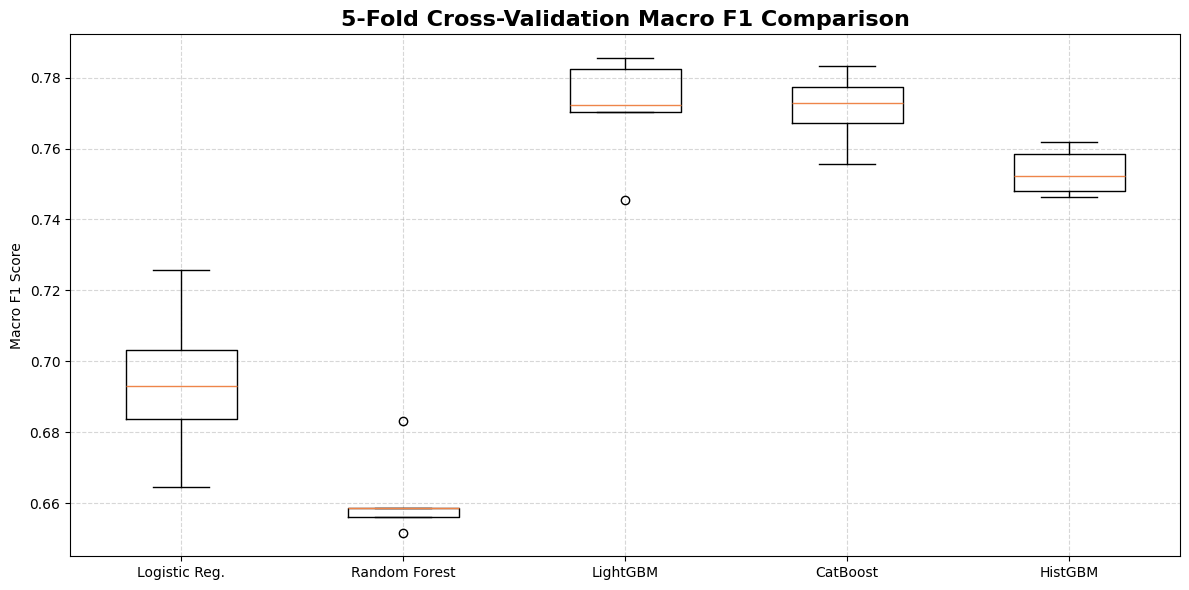

In [39]:
# creating one shared splitter so every model is scored on exactly the same 5 folds
cv_strategy = StratifiedKFold(n_splits = 5, shuffle = True, random_state = SEED)

# calculating the cross validation scores of all models (using macro F1 as scoring metric)
cv_log = cross_val_score(
    estimator = log_pipe,
    X = X_train,
    y = y_train,
    cv = cv_strategy,
    scoring = "f1_macro",
    n_jobs = -1
)
cv_rf = cross_val_score(
    estimator = rf_pipe,
    X = X_train,
    y = y_train,
    cv = cv_strategy,
    scoring = "f1_macro",
    n_jobs = -1
)
cv_lgbm = cross_val_score(
    estimator = lgbm_pipe,
    X = X_train,
    y = y_train,
    cv = cv_strategy,
    scoring = "f1_macro",
    n_jobs = -1
)
cv_hgb = cross_val_score(
    estimator = hgb_pipe,
    X = X_train,
    y = y_train,
    cv = cv_strategy,
    scoring = "f1_macro",
    n_jobs = -1
)

# manual cross-validation for CatBoost (workaround for sklearn compatibility), same folds as above
cv_cat = []
for train_idx, val_idx in cv_strategy.split(X_train, y_train):
    X_cv_train, X_cv_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_cv_train, y_cv_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    cat_cv_clone = clone(cat_pipe)
    cat_cv_clone.fit(X = X_cv_train, y = y_cv_train)
    y_cv_pred = np.array(cat_cv_clone.predict(X = X_cv_val)).ravel()
    cv_cat.append(f1_score(y_true = y_cv_val, y_pred = y_cv_pred, average = "macro"))
cv_cat = np.array(cv_cat)

# printing the results (everything else in the cell stays as it is)
print(
f"""Cross Validation Results of All Models (Macro F1)
{"—" * 50}
{"Logistic Regression":<25}: {np.mean(cv_log):.4f} ± {np.std(cv_log):.4f}
{"Random Forest":<25}: {np.mean(cv_rf):.4f} ± {np.std(cv_rf):.4f}
{"LightGBM":<25}: {np.mean(cv_lgbm):.4f} ± {np.std(cv_lgbm):.4f}
{"CatBoost":<25}: {np.mean(cv_cat):.4f} ± {np.std(cv_cat):.4f}
{"HistGradientBoosting":<25}: {np.mean(cv_hgb):.4f} ± {np.std(cv_hgb):.4f}"""
)


# visualizing the results for a better overview
plt.figure(figsize = (12, 6))

# creating a boxplot
plt.boxplot(
    x = [cv_log, cv_rf, cv_lgbm, cv_cat, cv_hgb],
    tick_labels = ["Logistic Reg.", "Random Forest", "LightGBM", "CatBoost", "HistGBM"]
)
plt.title(label = "5-Fold Cross-Validation Macro F1 Comparison", fontsize = 16, fontweight = "bold")
plt.ylabel(ylabel = "Macro F1 Score")
plt.grid(visible = True, linestyle = "--", alpha = 0.5)
plt.tight_layout()
plt.show()

<div style = "text-align: justify;">

**Key Insights:**

* **CatBoost** has the highest mean Macro F1 (0.7713 ± 0.0095), with **LightGBM** close behind (0.7712 ± 0.0141). The gap between them is under one point, smaller than the fold-to-fold spread, so CV cannot separate the two.
* **HistGradientBoosting** (0.7534 ± 0.0059) is slightly lower but the steadiest model across folds.
* **Logistic Regression** (0.6941 ± 0.0203) and **Random Forest** (0.6617 ± 0.0110) trail the boosters by roughly 6 to 11 points. That is much larger than the fold spread, so *boosting beats Logistic Regression and Random Forest* is the reliable conclusion.
* **Logistic Regression** varies the most between folds, and **Random Forest** is the weakest overall. Part of Random Forest’s result comes from its untuned, hand-set parameters.
* Overall, CV shows that boosting models generalize better than Logistic Regression and Random Forest here. It doesn’t settle which booster is best, which is why tuning follows.

</div>

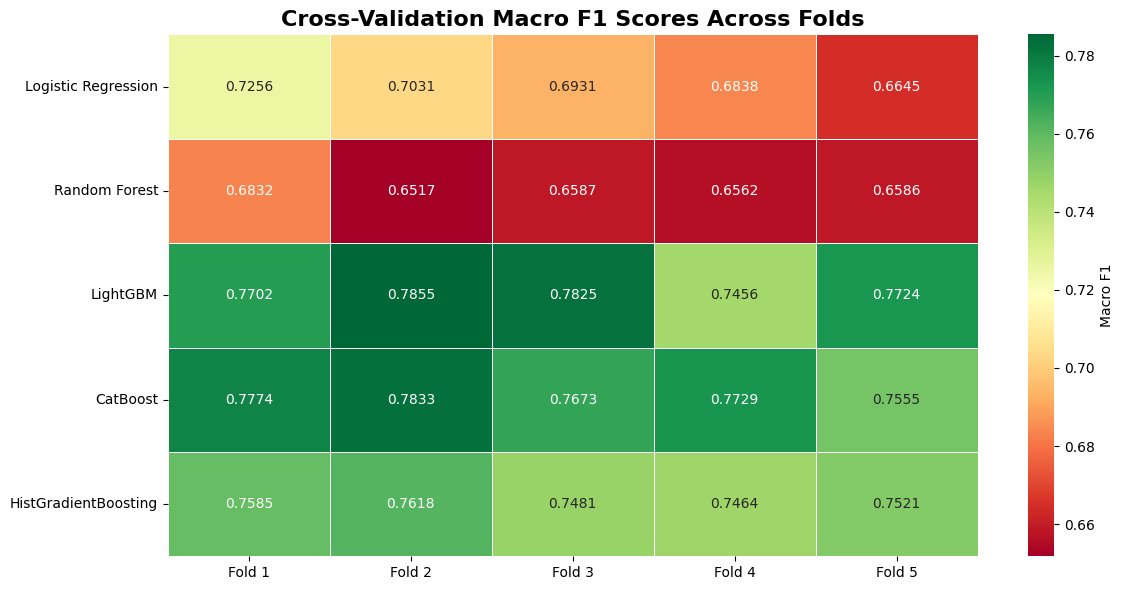

In [40]:
# creating a DataFrame for the heatmap using all 5 models' CV scores
heatmap_df = pd.DataFrame(
    {
        "Fold 1": [cv_log[0], cv_rf[0], cv_lgbm[0], cv_cat[0], cv_hgb[0]],
        "Fold 2": [cv_log[1], cv_rf[1], cv_lgbm[1], cv_cat[1], cv_hgb[1]],
        "Fold 3": [cv_log[2], cv_rf[2], cv_lgbm[2], cv_cat[2], cv_hgb[2]],
        "Fold 4": [cv_log[3], cv_rf[3], cv_lgbm[3], cv_cat[3], cv_hgb[3]],
        "Fold 5": [cv_log[4], cv_rf[4], cv_lgbm[4], cv_cat[4], cv_hgb[4]]
    }, 
    index = ["Logistic Regression", "Random Forest", "LightGBM", "CatBoost", "HistGradientBoosting"]
)

# setting up the plot
plt.figure(figsize = (12, 6))

# creating the heatmap
sns.heatmap(
    data = heatmap_df, 
    annot = True, 
    fmt = ".4f", 
    cmap = "RdYlGn", 
    cbar_kws = {"label": "Macro F1"}, 
    linewidths = 0.5, 
    linecolor = "white"
)
plt.title(label = "Cross-Validation Macro F1 Scores Across Folds", fontsize = 16, fontweight = "bold")
plt.tight_layout()
plt.show()

<div style = "text-align: justify;">

**Key Insights:**
- **CatBoost** and **LightGBM** are effectively tied in cross-validation. LightGBM leads in three folds (2, 3 and 5) and CatBoost in two (1 and 4), and the average difference between them is essentially zero.
- **CatBoost** is the steadier of the two, with a narrower range (**0.7555 to 0.7833**) than LightGBM (**0.7456 to 0.7855**), and its worst fold is higher.
- **HistGradientBoosting** is the most stable model (**0.7464 to 0.7618**), but it trails CatBoost in all five folds by about 1.8 points on average.
- Every booster beats **Logistic Regression** and **Random Forest** in every fold. The weakest booster fold (**0.7456**) is above the strongest LR or RF fold in the same split (**0.7256** at best).
- **Random Forest** is the lowest model in all five folds, and **Logistic Regression** varies the most (**0.6645 to 0.7256**), so it is the most sensitive to how the data is split.

</div>

### **Summary Table**

In [41]:
# the two lead-qualification classes
qualified_classes = ["Hot", "Warm"]

# share of Hot/Warm leads placed in their exact bucket (a Hot predicted as Warm counts as a miss)
def exact_bucket_recall(y_true, y_pred, classes):
    y_pred_series = pd.Series(np.array(y_pred).ravel(), index = y_true.index)
    mask = y_true.isin(classes)
    return (y_true[mask] == y_pred_series[mask]).mean()

# share of Hot/Warm leads predicted as Hot OR Warm (the question the business actually asks)
def qualified_recall(y_true, y_pred, classes):
    y_pred_series = pd.Series(np.array(y_pred).ravel(), index = y_true.index)
    mask = y_true.isin(classes)
    return y_pred_series[mask].isin(classes).mean()

# collecting everything model by model (same order everywhere)
model_names = ["Logistic Regression", "Random Forest", "LightGBM", "CatBoost", "HistGradientBoosting"]
y_preds = [y_pred_log, y_pred_rf, y_pred_lgbm, y_pred_cat, y_pred_hgb]
f1_trains = [f1_train_log, f1_train_rf, f1_train_lgbm, f1_train_cat, f1_train_hgb]
f1_tests = [f1_test_log, f1_test_rf, f1_test_lgbm, f1_test_cat, f1_test_hgb]
accuracies = [accuracy_log, accuracy_rf, accuracy_lgbm, accuracy_cat, accuracy_hgb]
cv_scores = [cv_log, cv_rf, cv_lgbm, cv_cat, cv_hgb]

# building the DataFrame
model_comparison = pd.DataFrame(
    {
        "Model": model_names,
        "Macro F1": f1_tests,
        "Weighted F1": [f1_score(y_true = y_test, y_pred = np.array(pred).ravel(), average = "weighted") for pred in y_preds],
        "Accuracy": accuracies,
        "Train-Test Gap": [f1_tr - f1_te for f1_tr, f1_te in zip(f1_trains, f1_tests)],
        "CV Mean F1": [np.mean(scores) for scores in cv_scores],
        "CV Std": [np.std(scores) for scores in cv_scores],
        "OVR Macro AUC": [auc_macro_ovr_log, auc_macro_ovr_rf, auc_macro_ovr_lgbm, auc_macro_ovr_cat, auc_macro_ovr_hgb],
        "OVR Weighted AUC": [auc_weighted_ovr_log, auc_weighted_ovr_rf, auc_weighted_ovr_lgbm, auc_weighted_ovr_cat, auc_weighted_ovr_hgb],
        "Qual-vs-Not AUC": [auc_score_log, auc_score_rf, auc_score_lgbm, auc_score_cat, auc_score_hgb],
        "Hot/Warm Exact Recall": [exact_bucket_recall(y_true = y_test, y_pred = pred, classes = qualified_classes) for pred in y_preds],
        "Qualified Recall": [qualified_recall(y_true = y_test, y_pred = pred, classes = qualified_classes) for pred in y_preds],
    }
)

# ranking by test Macro F1 (descending)
model_comparison = model_comparison.sort_values(by = "CV Mean F1", ascending = False).reset_index(drop = True)
model_comparison.insert(0, "Rank", range(1, len(model_comparison) + 1))

# one reusable style to bold the best values in each column
def style_table(df, caption, highest_cols, lowest_cols, formats):
    return (
        df.style
        .hide(axis = "index")
        .format(formats)
        .highlight_max(subset = highest_cols, props = "font-weight: bold; color: #1B7F3B;")
        .highlight_min(subset = lowest_cols, props = "font-weight: bold; color: #1B7F3B;")
        .set_caption(caption)
        .set_properties(**{"text-align": "center", "font-size": "10pt", "padding": "8px 10px"})
        .set_properties(subset = ["Model"], **{"text-align": "left", "font-weight": "600"})
        .set_table_styles([
            {"selector": "caption", "props": [("caption-side", "top"), ("font-size", "15pt"), ("font-weight", "bold"), ("text-align", "center"), ("padding", "8px 0")]},
            {"selector": "th", "props": [("background-color", "#2C3E50"), ("color", "white"), ("font-weight", "bold"), ("text-align", "center"), ("padding", "10px 10px")]},
            {"selector": "td", "props": [("border-bottom", "1px solid #ddd")]},
        ])
    )

# displaying the full comparison in one table
display(
    style_table(
        df = model_comparison,
        caption = "Model Performance Comparison (Cross-Validated Macro F1)",
        highest_cols = ["Macro F1", "Weighted F1", "Accuracy", "CV Mean F1", "OVR Macro AUC", "OVR Weighted AUC", "Qual-vs-Not AUC", "Hot/Warm Exact Recall", "Qualified Recall"],
        lowest_cols = ["Train-Test Gap", "CV Std"],
        formats = {
            "Macro F1": "{:.2%}", "Weighted F1": "{:.2%}", "Accuracy": "{:.2%}", "Train-Test Gap": "{:.2%}",
            "CV Mean F1": "{:.4f}", "CV Std": "{:.4f}",
            "OVR Macro AUC": "{:.2%}", "OVR Weighted AUC": "{:.2%}", "Qual-vs-Not AUC": "{:.2%}",
            "Hot/Warm Exact Recall": "{:.2%}", "Qualified Recall": "{:.2%}",
        },
    )
)

Rank,Model,Macro F1,Weighted F1,Accuracy,Train-Test Gap,CV Mean F1,CV Std,OVR Macro AUC,OVR Weighted AUC,Qual-vs-Not AUC,Hot/Warm Exact Recall,Qualified Recall
1,CatBoost,78.35%,78.68%,79.00%,21.61%,0.7713,0.0095,95.19%,94.66%,99.03%,81.29%,97.28%
2,LightGBM,75.06%,75.52%,75.78%,24.94%,0.7712,0.0141,94.17%,93.62%,98.89%,77.21%,96.60%
3,HistGradientBoosting,74.19%,75.04%,75.33%,25.81%,0.7534,0.0059,94.15%,93.69%,98.94%,76.19%,96.94%
4,Logistic Regression,71.53%,72.82%,73.22%,7.97%,0.6941,0.0203,93.46%,92.84%,98.87%,72.45%,95.24%
5,Random Forest,68.02%,72.67%,75.11%,9.61%,0.6617,0.0110,94.36%,93.69%,98.86%,72.11%,97.96%


<div style = "text-align: justify;">

**Key Insights:**
- **CatBoost** ranks first on every classification metric: Macro F1 (**78.35%**), weighted F1 (**78.68%**), accuracy (**79.00%**) and CV mean (**0.7713**). It leads LightGBM by 3.3 points on test but by only 0.01 points in CV, so the two are tied there.
- **Random Forest** has the fourth-highest accuracy (**75.11%**) but the lowest Macro F1 (**68.02%**). It does well on the large buckets and poorly on Hot, which is why Macro F1 is the right ranking metric here.
- **Logistic Regression (7.97%)** and **Random Forest (9.61%)** have the smallest train–test gaps, but their test and CV scores are the lowest. The small gap reflects limited capacity, not better generalisation. The three boosters show gaps of **21.61% to 25.81%**, CatBoost's being the smallest.
- **HistGradientBoosting** has the lowest CV spread (**0.0059**), and **Logistic Regression** the highest (**0.0203**).
- All five models separate qualified (Hot or Warm) from non-qualified leads almost perfectly (**Qualified-vs-Not AUC 98.86% to 99.03%**). They differ more on the individual buckets (**OVR Macro AUC 93.46% to 95.19%**), and CatBoost is best on every AUC.
- **Qualified Recall** is high for all models (**95.24% to 97.96%**). Random Forest's top figure is only two more leads than CatBoost's (288 vs 286 of 294), and it comes from pushing Hot leads into Warm. The real difference is in **Hot/Warm Exact Recall**, where CatBoost reaches **81.29%** against **72.11% to 77.21%** for the rest.
- Random Forest ranks second on OVR Macro AUC (**94.36%**) despite the lowest Macro F1, so its probabilities rank leads well but its hard predictions miss Hot leads.

</div>

<div style = "text-align: justify;">

### **Confusion Matrices**

We now compile the **Five** confusion matrices generated above into a single plot for easier comparison.

</div>

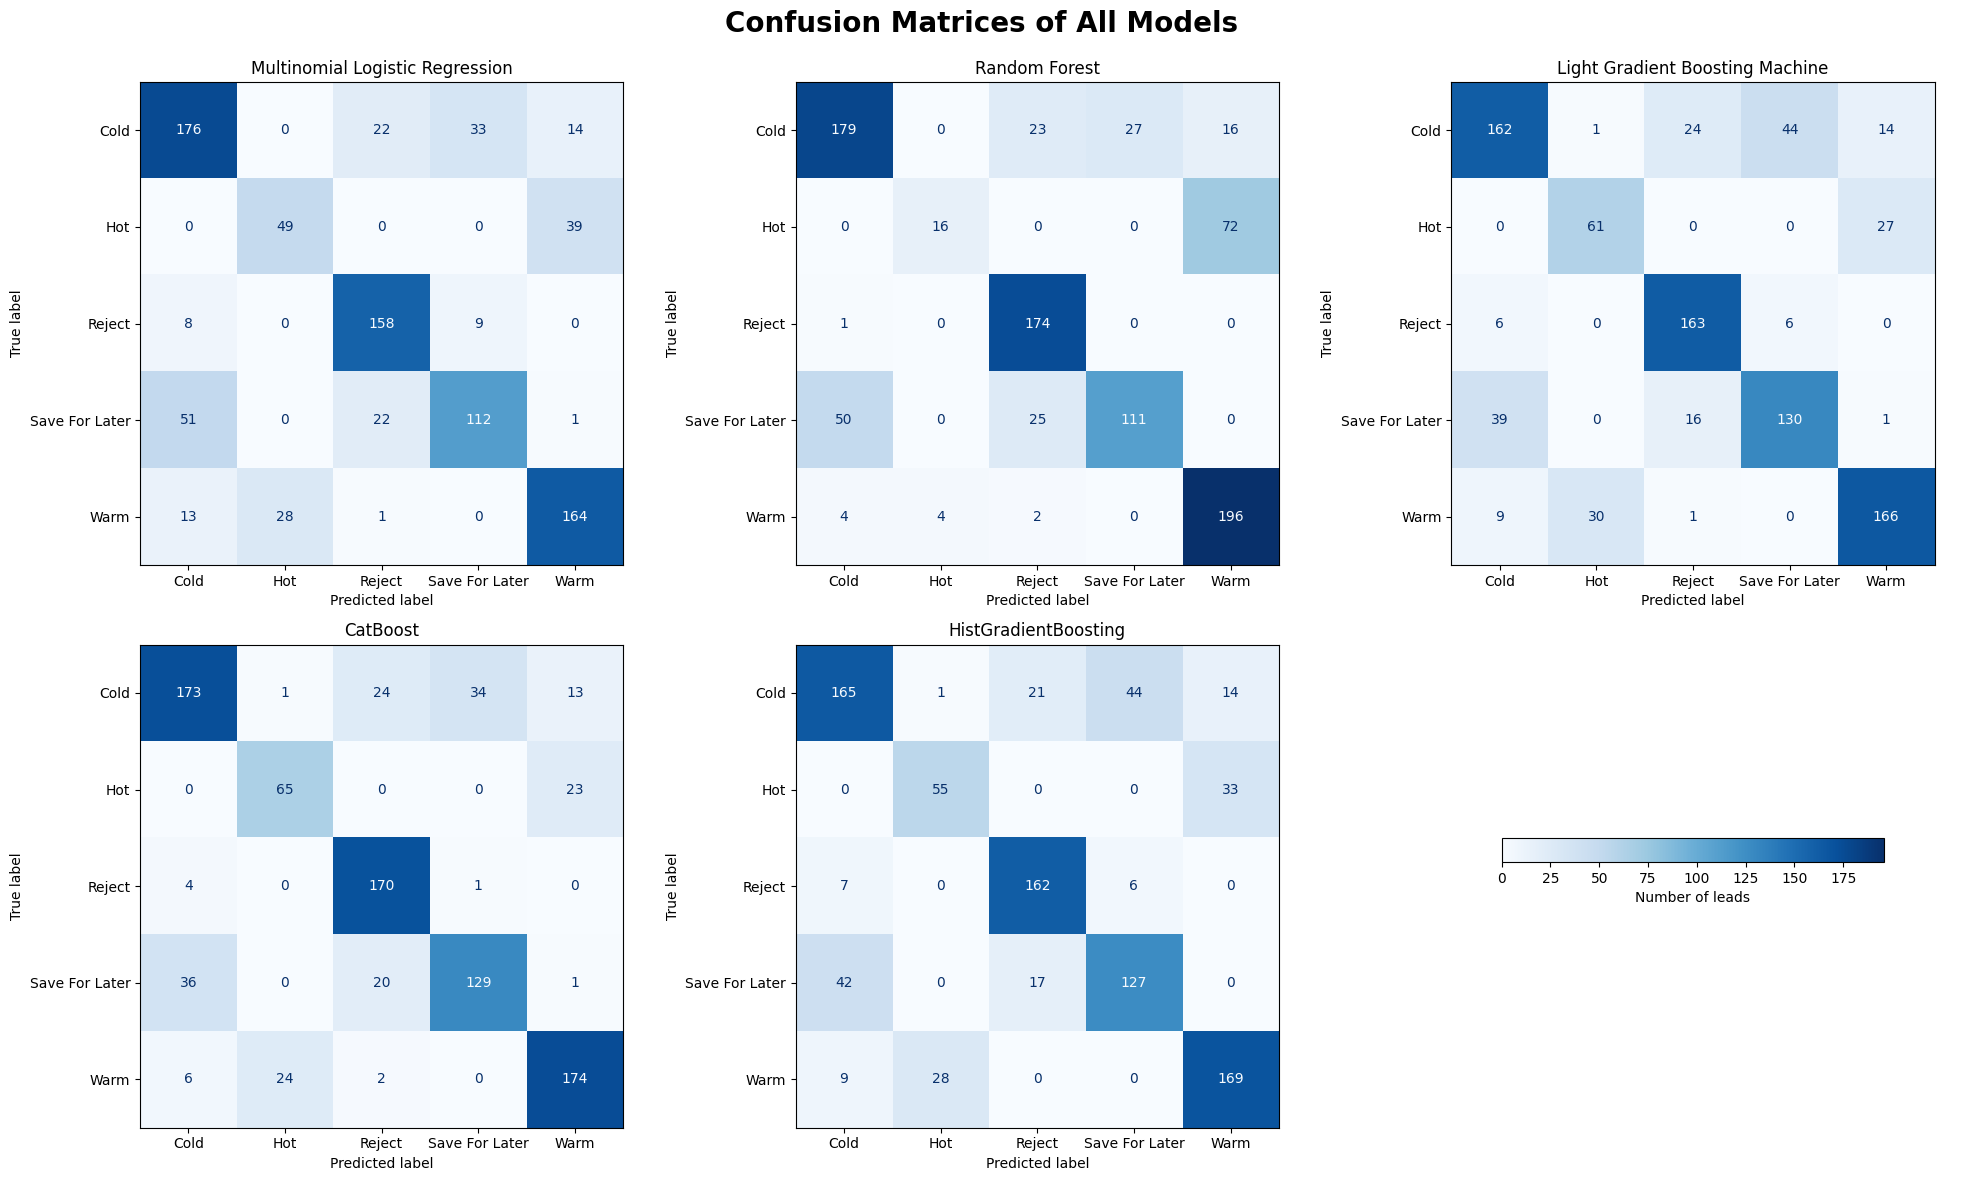

In [42]:
# grouping the matrices, class labels and titles in one place
cm_models = [
    ("Multinomial Logistic Regression", matrix_log, log_model.classes_),
    ("Random Forest", matrix_rf, rf_model.classes_),
    ("Light Gradient Boosting Machine", matrix_lgbm, lgbm_model.classes_),
    ("CatBoost", matrix_cat, cat_model.classes_),
    ("HistGradientBoosting", matrix_hgb, hgb_model.classes_),
]

# creating one common color scale for every panel: 0 up to the largest count in any matrix
vmax = max(matrix.max() for _, matrix, _ in cm_models)

# setting up the plot size for 2x3 display
fig, axes = plt.subplots(nrows = 2, ncols = 3, figsize = (20, 12))
fig.suptitle(t = "Confusion Matrices of All Models", fontsize = 20, fontweight = "bold")

# plotting each confusion matrix on the same scale (the individual colorbars are switched off)
for ax, (title, matrix, labels) in zip(axes.flat, cm_models):
    ConfusionMatrixDisplay(confusion_matrix = matrix, display_labels = labels).plot(
        ax = ax,
        cmap = "Blues",
        values_format = ",.0f",
        colorbar = False,
        im_kw = {"vmin": 0, "vmax": vmax}
    )
    ax.set_title(label = title, fontsize = 12)

# using the last empty panel for one shared colorbar
axes[1, 2].axis("off")
cax = axes[1, 2].inset_axes([0.15, 0.55, 0.7, 0.05])
fig.colorbar(
    ScalarMappable(
        norm = Normalize(vmin = 0, vmax = vmax),
        cmap = "Blues"
    ),
    cax = cax,
    orientation = "horizontal",
    label = "Number of leads"
)

# customizing the layout
plt.tight_layout()
plt.subplots_adjust(top = 0.92)
plt.show()

<div style = "text-align: justify;">

**Key Insights:**
* The errors fall in two neighbouring pairs: **Hot ↔ Warm** and **Cold ↔ Save For Later**. No model ever predicts a Hot lead as Cold, Reject or Save For Later, and **Reject** is the cleanest class (recall **90% to 99%**).
* **Cold ↔ Save For Later** is the largest source of errors for every model (**70 to 86** misplaced leads). CatBoost reduces it the most (**34** Cold predicted as Save For Later, **36** the other way), but none of the models solves it.
* **CatBoost** finds the most Hot leads (**65 of 88, 74%**) and keeps the Hot ↔ Warm errors balanced (**23** and **24**). It also places **174 of 206 Warm** and **170 of 175** Reject leads correctly.
* **Random Forest** sends **72 of 88** Hot leads to Warm (Hot recall **18%**). That is why its Warm recall is so high (**95%**) while its Macro F1 is the lowest.
* A model that mixes up Hot and Warm costs the business little, since both are qualified. For CatBoost only **8 of 294** qualified leads fall into a non-qualified bucket, and **15** non-qualified leads are flagged as qualified.

</div>

<div style = "text-align: justify;">

### **ROC Curves**

We now compile the **five** ROC AUC curves generated above into a single plot for easier comparison. For multiclass problems, we will use the One-vs-Rest (**OVR**) strategy to compute the ROC-AUC scores. This involves treating each class as the positive class and the rest as negative, then averaging the results.

</div>

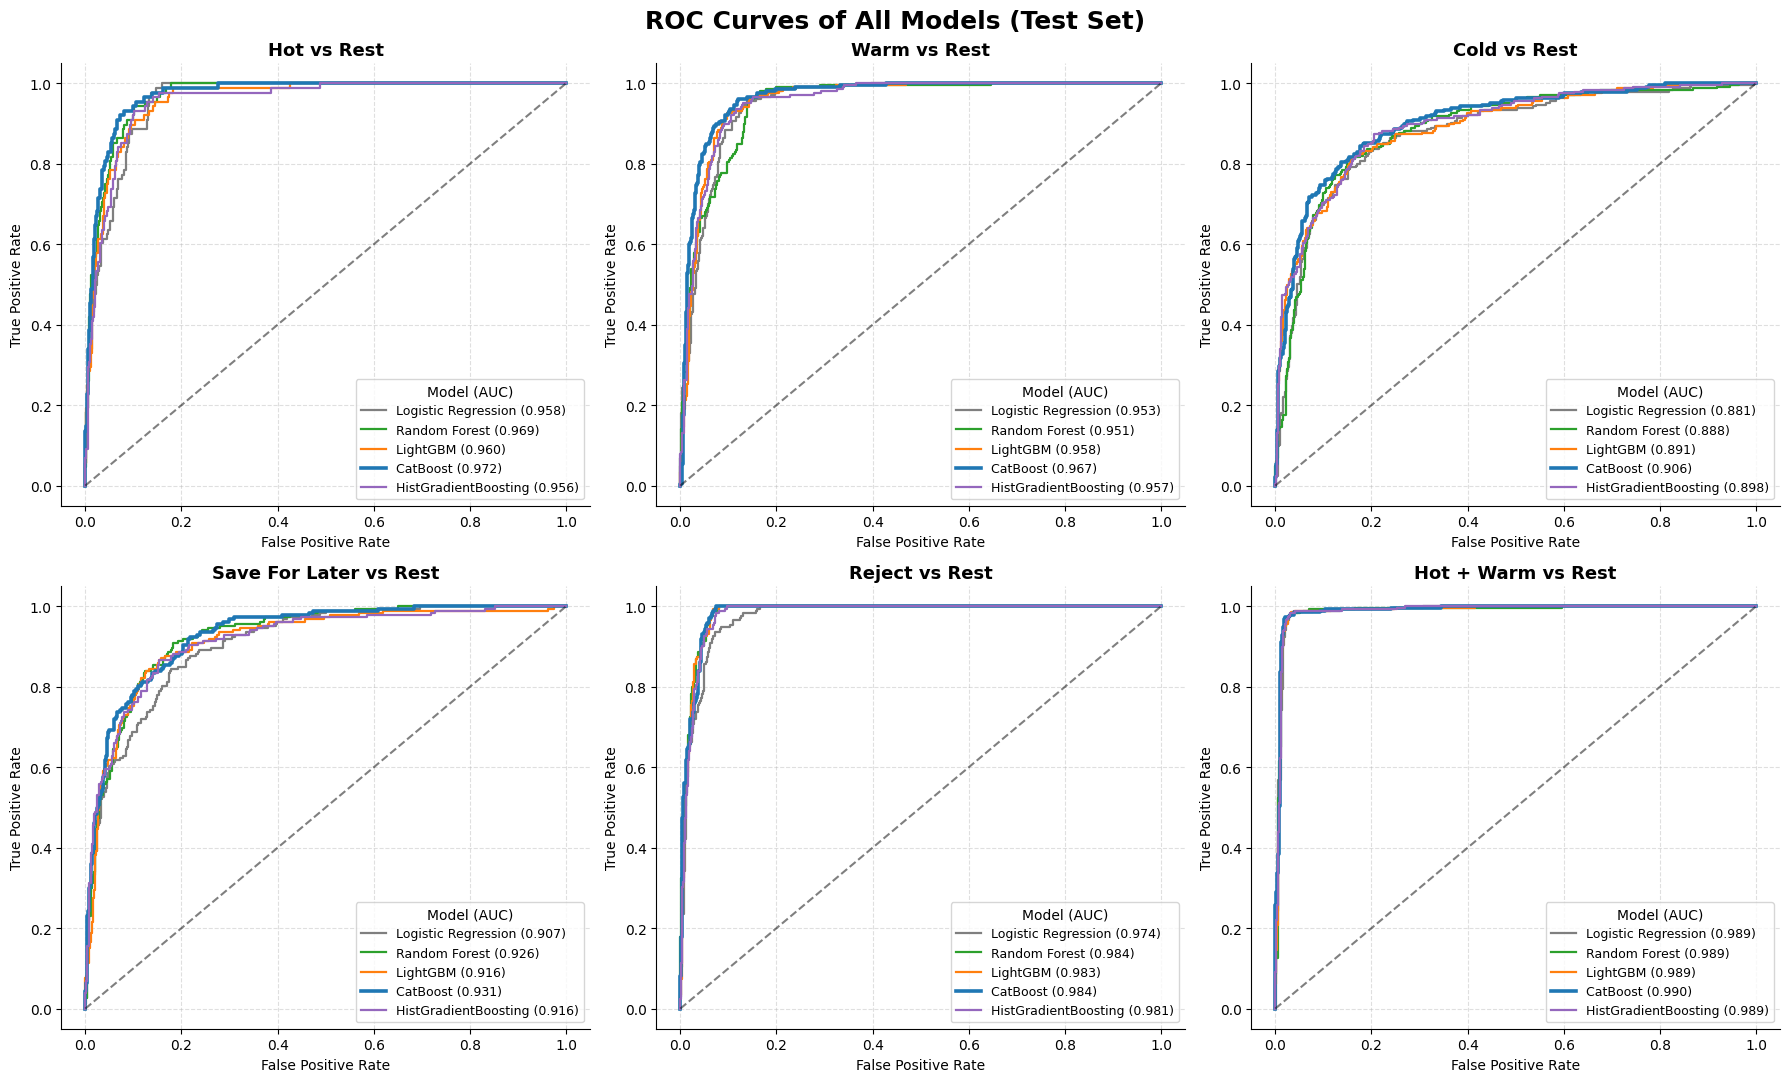

In [43]:
# creating a class order of the probability columns (same for every model)
classes_fitted = list(log_model.classes_)
class_order = ["Hot", "Warm", "Cold", "Save For Later", "Reject"]
roc_panels = class_order + ["Hot + Warm vs Rest"]

# setting up the plot
fig, axes = plt.subplots(nrows = 2, ncols = 3, figsize = (18, 11))

# creating one dictionary that holds every model's probabilities, colour and line width
plot_models = {
    "Logistic Regression": {"prob": y_prob_log, "color": "tab:gray", "lw": 1.6},
    "Random Forest": {"prob": y_prob_rf, "color": "tab:green", "lw": 1.6},
    "LightGBM": {"prob": y_prob_lgbm, "color": "tab:orange", "lw": 1.6},
    "CatBoost": {"prob": y_prob_cat, "color": "tab:blue", "lw": 2.6},
    "HistGradientBoosting": {"prob": y_prob_hgb, "color": "tab:purple", "lw": 1.6},
}

# plotting the ROC curves for each model and each class (or Hot/Warm vs Rest)
for ax, panel in zip(axes.flat, roc_panels):
    for name, info in plot_models.items():
        if panel == "Hot + Warm vs Rest":
            
            # the business question: is this lead qualified (Hot or Warm) or not?
            y_true_bin = y_test.isin(["Hot", "Warm"]).astype(int)
            y_score = info["prob"][:, [classes_fitted.index("Hot"), classes_fitted.index("Warm")]].sum(axis = 1)
        else:
            
            # one-vs-rest for a single class
            y_true_bin = (y_test == panel).astype(int)
            y_score = info["prob"][:, classes_fitted.index(panel)]

        fpr, tpr, _ = roc_curve(y_true = y_true_bin, y_score = y_score)
        auc = roc_auc_score(y_true = y_true_bin, y_score = y_score)
        ax.plot(fpr, tpr, color = info["color"], linewidth = info["lw"], label = f"{name} ({auc:.3f})")

    ax.plot([0, 1], [0, 1], linestyle = "--", color = "black", alpha = 0.5)
    ax.set_title(label = panel if panel == "Hot + Warm vs Rest" else f"{panel} vs Rest", fontsize = 13, fontweight = "bold")
    ax.set_xlabel(xlabel = "False Positive Rate")
    ax.set_ylabel(ylabel = "True Positive Rate")
    ax.grid(visible = True, linestyle = "--", alpha = 0.4)
    ax.legend(title = "Model (AUC)", loc = "lower right", fontsize = 9)

# customizing the layout
fig.suptitle(t = "ROC Curves of All Models (Test Set)", fontsize = 18, fontweight = "bold")
plt.tight_layout()
sns.despine()
plt.show()

Since the above combined ROC AUC plots are difficult to read, we will also generate a **zoomed-in version** of the ROC AUC curves to better visualize the differences between the models.

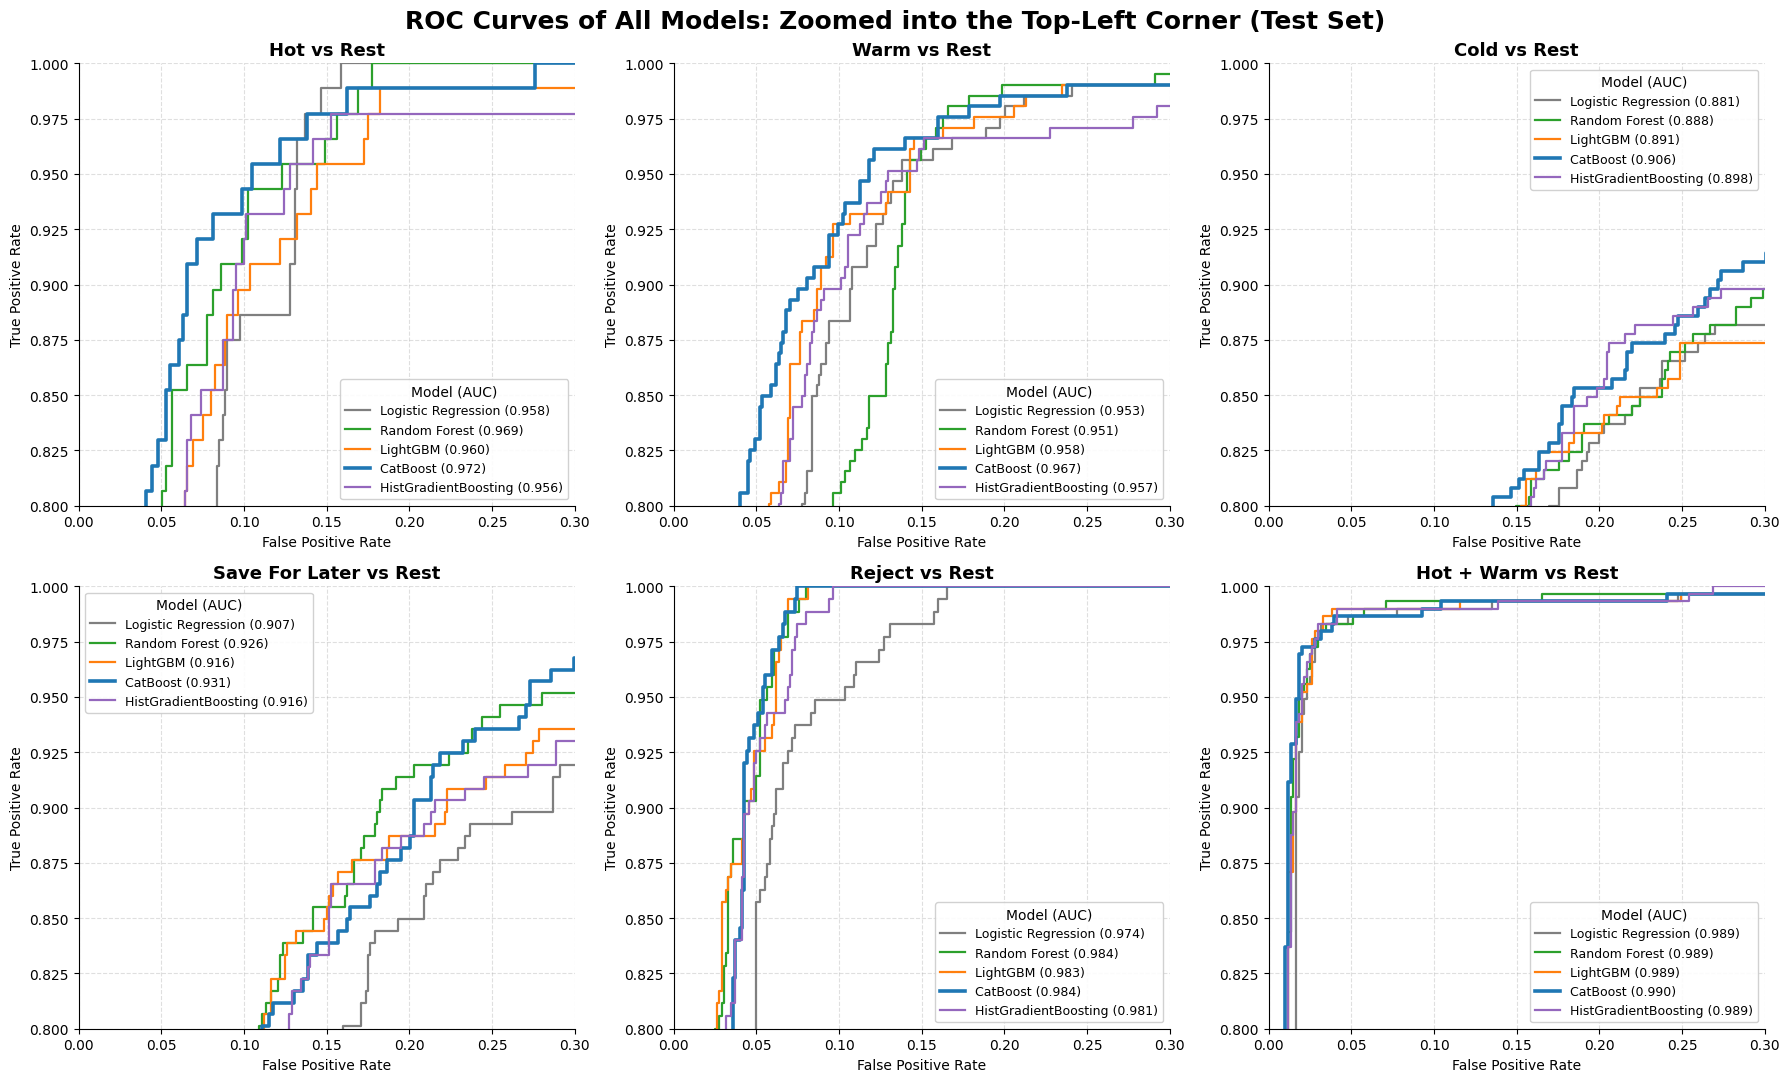

In [44]:
# setting up the zoom window (top-left corner of the ROC space)
zoom_xlim = (0.0, 0.3)     # False Positive Rate
zoom_ylim = (0.8, 1.0)     # True Positive Rate

# setting up the plot
fig, axes = plt.subplots(nrows = 2, ncols = 3, figsize = (18, 11))

# plotting the ROC curves for each model and each class (or Hot/Warm vs Rest), same as before
for ax, panel in zip(axes.flat, roc_panels):
    for name, info in plot_models.items():
        if panel == "Hot + Warm vs Rest":

            # the business question: is this lead qualified (Hot or Warm) or not?
            y_true_bin = y_test.isin(["Hot", "Warm"]).astype(int)
            y_score = info["prob"][:, [classes_fitted.index("Hot"), classes_fitted.index("Warm")]].sum(axis = 1)
        else:

            # one-vs-rest for a single class
            y_true_bin = (y_test == panel).astype(int)
            y_score = info["prob"][:, classes_fitted.index(panel)]

        fpr, tpr, _ = roc_curve(y_true = y_true_bin, y_score = y_score)
        auc = roc_auc_score(y_true = y_true_bin, y_score = y_score)
        ax.plot(fpr, tpr, color = info["color"], linewidth = info["lw"], label = f"{name} ({auc:.3f})")

    # zooming into the top-left corner
    ax.set_xlim(zoom_xlim)
    ax.set_ylim(zoom_ylim)
    ax.set_title(label = (panel if panel == "Hot + Warm vs Rest" else f"{panel} vs Rest"), fontsize = 13, fontweight = "bold")
    ax.set_xlabel(xlabel = "False Positive Rate")
    ax.set_ylabel(ylabel = "True Positive Rate")
    ax.grid(visible = True, linestyle = "--", alpha = 0.4)
    ax.legend(title = "Model (AUC)", loc = "lower right", fontsize = 9, framealpha = 0.9)

# manually setting two legends to avoid overlapping
axes[0, 2].legend(title = "Model (AUC)", loc = "upper right", fontsize = 9, framealpha = 0.9)
axes[1, 0].legend(title = "Model (AUC)", loc = "upper left", fontsize = 9, framealpha = 0.9)

# customizing the layout
fig.suptitle(t = "ROC Curves of All Models: Zoomed into the Top-Left Corner (Test Set)", fontsize = 18, fontweight = "bold")
plt.tight_layout()
sns.despine()   
plt.show()

<div style = "text-align: justify;">

**Key Insights:**
- **CatBoost** has the highest AUC in every panel, except where it ties: Hot (**0.972**), Warm (**0.967**), Cold (**0.906**), Save For Later (**0.931**), Reject (**0.984**, tied with Random Forest) and Hot + Warm vs Rest (**0.990**). Its edge is under 1 point against the runner-up in every panel, and about 1 to 2.5 points against the weakest model.
- **Cold** (**0.881 to 0.906**) and **Save For Later** (**0.907 to 0.931**) are the hardest classes to rank for every model. This matches the confusion matrices, where those two buckets are the most mixed up.
- **Hot + Warm vs Rest** is near-perfect for all five models (**0.989 to 0.990**), and the curves overlap. The qualified-vs-not-qualified screen is easy whichever model is used, and the model choice matters mainly for the finer bucket assignment.
- **Random Forest** ranks Hot leads well (AUC **0.969**, second to CatBoost) despite its poor Hot recall. Its probabilities are informative, but its predicted labels underpredict Hot.

</div>

<div style = "text-align: justify;">

## Final Model Selection: **CatBoost Classifier**

Models are compared on cross-validated Macro F1, which is the fair basis for choosing one. Test results are shown for reference, and they agree with the CV ranking.

- **Cross-validation:** best mean Macro F1 (**0.7713**), a tighter spread than LightGBM (**±0.0095 vs ±0.0141**) and the highest worst-fold score (**0.7555**). LightGBM is tied on the mean (**0.7712**), so the lower spread settles it.
- **Test performance:** Macro F1 **78.35%**, 3.3 points above LightGBM, with the best weighted F1, accuracy and AUCs.
- **Business fit:** best Qualified-vs-Not AUC (**99.03%**) and the best placement of Hot and Warm leads in their exact bucket (**81.29%** against **72.11% to 77.21%**). All five models catch 95% to 98% of qualified leads, so CatBoost's real advantage is telling Hot from Warm.

**On overfitting:** CatBoost's train–test gap is large (**21.61%**, with training Macro F1 close to 100%). Logistic Regression (**7.97%**) and Random Forest (**9.61%**) have smaller gaps, but their scores are lower, so their small gaps reflect limited capacity. The gap is a reason to regularise CatBoost, not to reject it, which is the purpose of the tuning stage that follows. The model deployed in this project is the tuned CatBoost.

</div>

### **Hyperparameter Tuning**

<div style = "text-align: justify;">

The baseline CatBoost model memorizes the training data (train–test Macro F1 gap of about 21%), so tuning here focuses on the parameters that control model complexity and regularization: the number of trees, learning rate, tree depth, L2 penalty, row and feature subsampling, and split randomness.

We use **Optuna** with its **TPE** (Tree-structured Parzen Estimator) sampler for **three** reasons:
1. **Every evaluation is expensive.** One trial means a 5-fold cross-validation, i.e. five CatBoost fits. A grid over eight parameters would need hundreds of thousands of combinations, which is impossible here.
2. **The search space is mixed.** Learning rate, L2 penalty and randomness are continuous (searched on a log scale), depth and the number of trees are integers, and class weighting is categorical. Optuna handles all of these in one space.
3. **It learns from earlier trials.** Random search samples blindly. TPE starts with 15 random trials, then samples more often from the regions that scored well, which gets more out of a limited budget of 60 trials.

**Design choices:**
* **Same folds for every trial.** All trials are scored on the same 5 stratified folds, so differences between trials come from the parameters and not from the splits.
* **Preprocessing inside each fold.** A fresh pipeline is fitted per fold, so the encoders and scaling never see the validation fold.
* **No early stopping.** Early stopping would use the validation fold both to stop training and to score the model, which makes the CV score optimistic. The number of trees is tuned directly instead.
* **Depth capped at 6.** The baseline's depth of 7 overfit the most, and each extra level roughly doubles the cost.
* **Class weighting is a tuned option.** `auto_class_weights` is searched like any other parameter, so class weighting is decided by cross-validation and not by looking at test results.
* **Test set not used in the search.** Tuning uses cross-validation on the training set only. The test set is used afterwards to evaluate the final model.

Because CV scores are noisy (about ±1 point), the tuned model is judged on its stability and generalisation gap as well as its score. Both the base and the tuned model are also re-scored on a new set of folds, because the best trial's CV score is the maximum of many noisy trials and is therefore slightly optimistic.

> *Folds run in parallel (one worker per fold). Runtime depends on the number of CPU cores.*

</div>

In [45]:
# suppressing Optuna's per-trial logging
optuna.logging.set_verbosity(optuna.logging.WARNING)

# defining fixed parameters for all CatBoost runs (the tuned ones are added in every trial)
fixed_params = {
    "bootstrap_type": "Bernoulli",
    "border_count": 128,
    "random_state": SEED,
    "thread_count": 1,
    "verbose": False,
    "allow_writing_files": False,
    "task_type": "CPU"
}

# defining the search space
def suggest_params(trial):
    return {
        "iterations": trial.suggest_int("iterations", 300, 1200, step = 100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log = True),
        "depth": trial.suggest_int("depth", 3, 6),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 30, log = True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "rsm": trial.suggest_float("rsm", 0.4, 1.0),
        "random_strength": trial.suggest_float("random_strength", 0.1, 10, log = True),
        "auto_class_weights": trial.suggest_categorical("auto_class_weights", [None, "SqrtBalanced", "Balanced"]),
    }

# scoring one fold: a fresh pipeline is fitted, so the preprocessing is learned from the training part of the fold only
def score_fold(params, train_idx, val_idx):
    fold_pipe = Pipeline(
        steps = [
            ("preprocess", build_preprocessor(scale_numeric = False)),
            ("model", CatBoostClassifier(**params, **fixed_params))
        ]
    )
    fold_pipe.fit(X = X_train.iloc[train_idx], y = y_train.iloc[train_idx])
    y_cv_pred = np.array(fold_pipe.predict(X = X_train.iloc[val_idx])).ravel()
    return f1_score(y_true = y_train.iloc[val_idx], y_pred = y_cv_pred, average = "macro")

# defining the Optuna objective: mean macro F1 over the same 5 folds (cv_strategy) in every trial, one worker per fold
def objective(trial):
    params = suggest_params(trial)
    fold_scores = Parallel(n_jobs = 5)(
        delayed(score_fold)(params, train_idx, val_idx)
        for train_idx, val_idx in cv_strategy.split(X_train, y_train)
    )
    return np.mean(fold_scores)

# running the Optuna study (TPE sampler: the first 15 trials are random, then it learns from the results)
study = optuna.create_study(
    direction = "maximize",
    sampler = optuna.samplers.TPESampler(seed = SEED, n_startup_trials = 15)
)
study.optimize(func = objective, n_trials = 60, show_progress_bar = True)

# extracting the best parameters and score
best_params = study.best_params
best_score = study.best_value

print(
f"""Optuna Optimization Complete
{"─" * 50}
Best Parameters: {best_params}
Best Cross-Validation Macro F1: {best_score:.4f}
"""
)

  0%|          | 0/60 [00:00<?, ?it/s]

Optuna Optimization Complete
──────────────────────────────────────────────────
Best Parameters: {'iterations': 900, 'learning_rate': 0.02391821952287803, 'depth': 4, 'l2_leaf_reg': 1.2292091009654584, 'subsample': 0.6490605494922798, 'rsm': 0.5879544010051231, 'random_strength': 3.3214164429158988, 'auto_class_weights': None}
Best Cross-Validation Macro F1: 0.7852



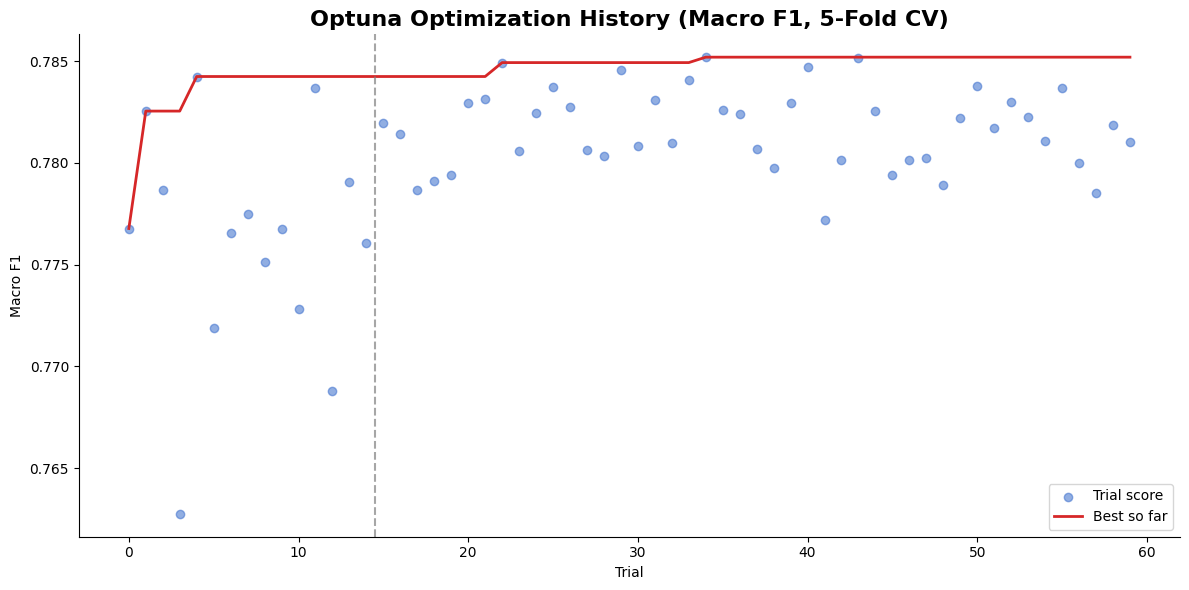

In [46]:
# plotting how the search progressed (each dot is one trial, the line is the best score so far)
trials_df = study.trials_dataframe()

# visualizing the optimization history
plt.figure(figsize = (12, 6))
plt.scatter(
    x = trials_df["number"],
    y = trials_df["value"],
    alpha = 0.6,
    label = "Trial score"
)
plt.plot(
    trials_df["number"],
    trials_df["value"].cummax(),
    color = "tab:red",
    linewidth = 2,
    label = "Best so far"
)

# adding a vertical line to indicate the end of the random search phase (15 trials)
plt.axvline(
    x = 14.5,
    linestyle = "--",
    color = "gray", 
    alpha = 0.7
)
plt.title(label = "Optuna Optimization History (Macro F1, 5-Fold CV)", fontsize = 16, fontweight = "bold")
plt.xlabel(xlabel = "Trial")
plt.ylabel(ylabel = "Macro F1")
plt.legend()
plt.tight_layout()
sns.despine()
plt.show()

In [47]:
# creating the final tuned pipeline with the best parameters and fitting it on the full training set
cat_tuned_pipe = Pipeline(
    steps = [
        ("preprocess", build_preprocessor(scale_numeric = False)),
        ("model", CatBoostClassifier(**best_params, **fixed_params))
    ]
)
cat_tuned_pipe.fit(X = X_train, y = y_train)
cat_tuned = cat_tuned_pipe.named_steps["model"]

# calculating the predictions for test and train datasets
y_pred_tuned = np.array(cat_tuned_pipe.predict(X = X_test)).ravel()
y_pred_train_tuned = np.array(cat_tuned_pipe.predict(X = X_train)).ravel()

# calculating the accuracy, macro F1 and the classification report
accuracy_tuned = accuracy_score(y_true = y_test, y_pred = y_pred_tuned)
accuracy_train_tuned = accuracy_score(y_true = y_train, y_pred = y_pred_train_tuned)
f1_train_tuned = f1_score(y_true = y_train, y_pred = y_pred_train_tuned, average = "macro")
f1_test_tuned = f1_score(y_true = y_test, y_pred = y_pred_tuned, average = "macro")
report_tuned = classification_report(y_true = y_test, y_pred = y_pred_tuned)

# calculating the predicted probabilities and the ROC-AUC scores (OVR macro, OVR weighted, qualified-vs-not)
y_prob_tuned = cat_tuned_pipe.predict_proba(X = X_test)
auc_macro_ovr_tuned = roc_auc_score(
    y_true = y_test,
    y_score = y_prob_tuned,
    multi_class = "ovr",
    average = "macro"
)
auc_weighted_ovr_tuned = roc_auc_score(
    y_true = y_test,
    y_score = y_prob_tuned,
    multi_class = "ovr",
    average = "weighted"
)
qualified_idx_tuned = [list(cat_tuned.classes_).index(c) for c in qualified_classes]
p_qualified_tuned = y_prob_tuned[:, qualified_idx_tuned].sum(axis = 1)
auc_score_tuned = roc_auc_score(y_true = y_test_bin_auc, y_score = p_qualified_tuned)

# creating a helper that returns the macro F1 of every fold for any pipeline (a fresh clone is fitted in each fold)
def cv_macro_f1(pipe, splitter):
    def one_fold(train_idx, val_idx):
        fold_pipe = clone(pipe)
        fold_pipe.fit(X = X_train.iloc[train_idx], y = y_train.iloc[train_idx])
        y_cv_pred = np.array(fold_pipe.predict(X = X_train.iloc[val_idx])).ravel()
        return f1_score(y_true = y_train.iloc[val_idx], y_pred = y_cv_pred, average = "macro")
    return np.array(Parallel(n_jobs = 5)(delayed(one_fold)(tr, va) for tr, va in splitter.split(X_train, y_train)))

# cross-validation scores of the tuned model on the same folds that were used for tuning
cv_tuned = cv_macro_f1(pipe = cat_tuned_pipe, splitter = cv_strategy)

# the best CV score is the maximum over many noisy trials, so it is slightly optimistic: re-scoring the base and the tuned model on new folds
fresh_cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 2026)
cv_fresh_base = cv_macro_f1(pipe = cat_pipe, splitter = fresh_cv)
cv_fresh_tuned = cv_macro_f1(pipe = cat_tuned_pipe, splitter = fresh_cv)

# displaying the results
print(
f"""
Optuna TPE — Tuned CatBoost Classifier Performance
{"─" * 50}
Macro F1 (Train):          {f1_train_tuned:.2%}
Macro F1 (Test):           {f1_test_tuned:.2%}
Train-Test Gap:            {f1_train_tuned - f1_test_tuned:.2%}
Accuracy (Test):           {accuracy_tuned:.2%}

CV Macro F1 (tuning folds): {np.mean(cv_tuned):.4f} ± {np.std(cv_tuned):.4f}

OVR Macro AUC:             {auc_macro_ovr_tuned:.2%}
OVR Weighted AUC:          {auc_weighted_ovr_tuned:.2%}
Qual-vs-Not AUC:           {auc_score_tuned:.2%}

{report_tuned}"""
)

print(
f"""Base vs Tuned Catboost
{"─" * 50}
{"":28}{"Base":>12}{"Tuned":>12}
{"Macro F1 (Test)":28}{f1_test_cat:>12.2%}{f1_test_tuned:>12.2%}
{"Train-Test Gap":28}{f1_train_cat - f1_test_cat:>12.2%}{f1_train_tuned - f1_test_tuned:>12.2%}
{"CV on new folds (mean)":28}{np.mean(cv_fresh_base):>12.4f}{np.mean(cv_fresh_tuned):>12.4f}
{"CV on new folds (std)":28}{np.std(cv_fresh_base):>12.4f}{np.std(cv_fresh_tuned):>12.4f}
"""
)


Optuna TPE — Tuned CatBoost Classifier Performance
──────────────────────────────────────────────────
Macro F1 (Train):          86.13%
Macro F1 (Test):           78.72%
Train-Test Gap:            7.41%
Accuracy (Test):           79.22%

CV Macro F1 (tuning folds): 0.7852 ± 0.0135

OVR Macro AUC:             95.55%
OVR Weighted AUC:          95.04%
Qual-vs-Not AUC:           99.08%

                precision    recall  f1-score   support

          Cold       0.78      0.71      0.74       245
           Hot       0.74      0.76      0.75        88
        Reject       0.79      0.98      0.87       175
Save For Later       0.78      0.67      0.72       186
          Warm       0.85      0.85      0.85       206

      accuracy                           0.79       900
     macro avg       0.79      0.79      0.79       900
  weighted avg       0.79      0.79      0.79       900

Base vs Tuned Catboost
──────────────────────────────────────────────────
                                

## Catboost Classifier: Optuna Final Model Evaluation

### **Top Features of the Model**

The top features of the CatBoost model can be figured out in a couple of ways. Below, we explore **two** possible ways:

1. CatBoost's in-built system (using `feature_importances_`)
2. Using SHAP (Shapley Additive Explanations) values

After extracting the top features, we will generate some overall insights based on these features.

#### Using CatBoost's In-Built Feature Importance System

In [48]:
# getting the transformed test data (the exact columns the tuned model sees) and the feature names
X_test_transformed = cat_tuned_pipe.named_steps["preprocess"].transform(X = X_test)
feature_names_tuned = X_test_transformed.columns.tolist()

# displaying the top 10 most important features (by feature importance)
print("Top 10 Most Important Features of the tuned CatBoost Classifier")
print("─" * 70)

feature_importance_cat_tuned = pd.DataFrame(
    {
        "feature": feature_names_tuned,
        "importance": cat_tuned.feature_importances_
    }
).sort_values(by = "importance", ascending = False).head(10)

for idx, row in feature_importance_cat_tuned.iterrows():
    print(f"{row['feature']:30s}: {row['importance']:>10.4f}")

Top 10 Most Important Features of the tuned CatBoost Classifier
──────────────────────────────────────────────────────────────────────
urgency_days                  :    34.8164
expected_monthly_volume_liters:    20.7879
google_review_count           :    15.4457
credibility_level             :     4.0832
purchase_stage                :     2.8463
distance_km                   :     1.9903
lead_source_Facebook Page     :     1.6188
order_frequency_Weekly        :     1.4074
has_phone_Yes                 :     1.3551
employee_estimate             :     1.1674


<div style = "text-align: justify;">

**Interpretation of the Numbers:**
* These are CatBoost's built-in importance scores. They always add up to **100** across all features, so each value is that feature's share of the model's total importance.
* A higher share means the model's predictions change more when that feature's value changes.

**Key Insights:**
* `urgency_days` leads with **34.8%**, followed by `expected_monthly_volume_liters` (**20.8%**) and `google_review_count` (**15.4%**). These three together account for about **71%** of the total importance.
* `credibility_level` (**4.1%**) and `purchase_stage` (**2.8%**) form a clear second tier, far below the top three.
* The other top-10 features (`distance_km`, `lead_source_Facebook Page`, `order_frequency_Weekly`, `has_phone_Yes`, `employee_estimate`) each hold only about **1–2%**, so they fine-tune decisions rather than drive them.
* The top 10 hold about **86%** of the importance, leaving roughly 14% shared by the other 79 features.

</div>

#### Using SHAP Values

***Shapley value** is a game-theoretic approach to understand contribution of a prediction*. To put it in simple terms, a Shapley value tells us that why a prediction value is high or low, and what lead to the increase or decrease.

##### **Across the entire dataset, which features matter the most on average?**

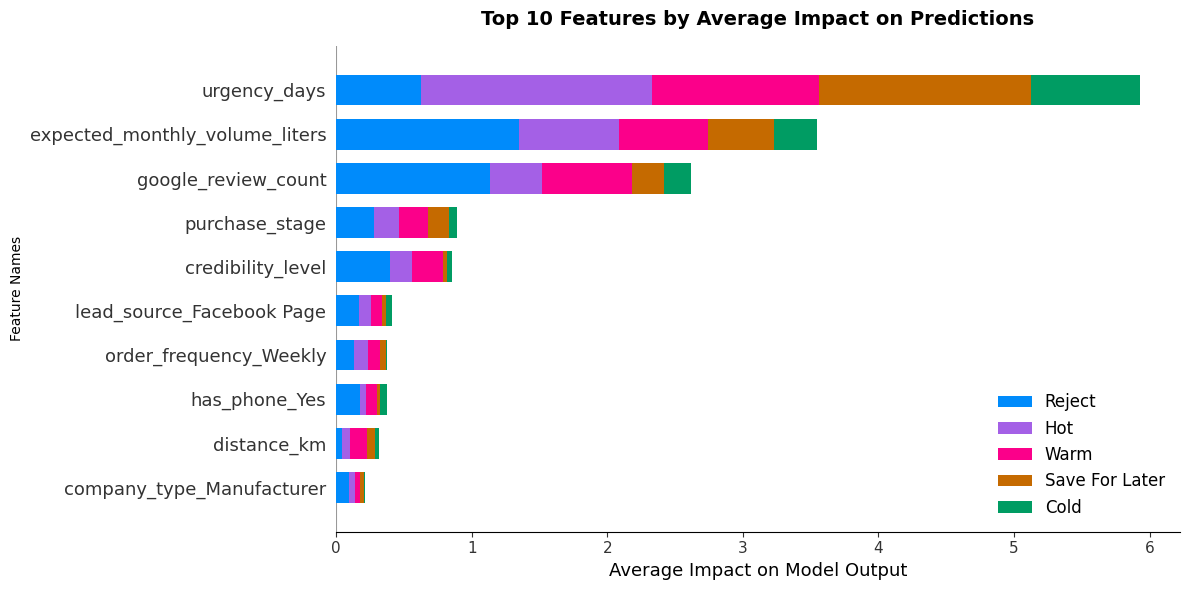

In [49]:
# initializing the SHAP explainer for the tuned CatBoost model and explaining the test set
explainer = shap.TreeExplainer(model = cat_tuned)
shap_values = explainer.shap_values(X = X_test_transformed)

# taking the mean of absolute SHAP values across all classes for the bar plot
shap.summary_plot(
    shap_values = shap_values,
    feature_names = feature_names_tuned,
    plot_type = "bar",
    max_display = 10,
    show = False,
    class_names = cat_tuned.classes_.tolist()
)
plt.gcf().set_size_inches(12, 6)
plt.title("Top 10 Features by Average Impact on Predictions", fontsize = 14, fontweight = "bold", pad = 15)
plt.xlabel("Average Impact on Model Output")
plt.ylabel("Feature Names")
plt.tight_layout()
plt.show()

<div style = "text-align: justify;">

**Interpretation of the Graph:**
* Each bar shows how much a feature moves the model's output on average (mean absolute SHAP value). The colours show how that impact is split across the five buckets.

**Key Insights:**
* The same three features lead: `urgency_days` (about **5.9**), `expected_monthly_volume_liters` (about **3.5**) and `google_review_count` (about **2.6**). Every other feature is below **1**.
* Urgency acts mostly on **Hot, Warm and Save For Later**, while volume and reviews act mostly on **Reject**.
* `purchase_stage` and `credibility_level` come next (about **0.9** each) and, like the rest, mostly act on Reject, Warm and Hot. CatBoost's own ranking puts credibility first, but both methods agree these two form the second tier.
* Lead source, order frequency, phone availability, distance and company type all have small bars (below **0.4**).

</div>

##### **For one specific company, why did the model predict a particular value??**

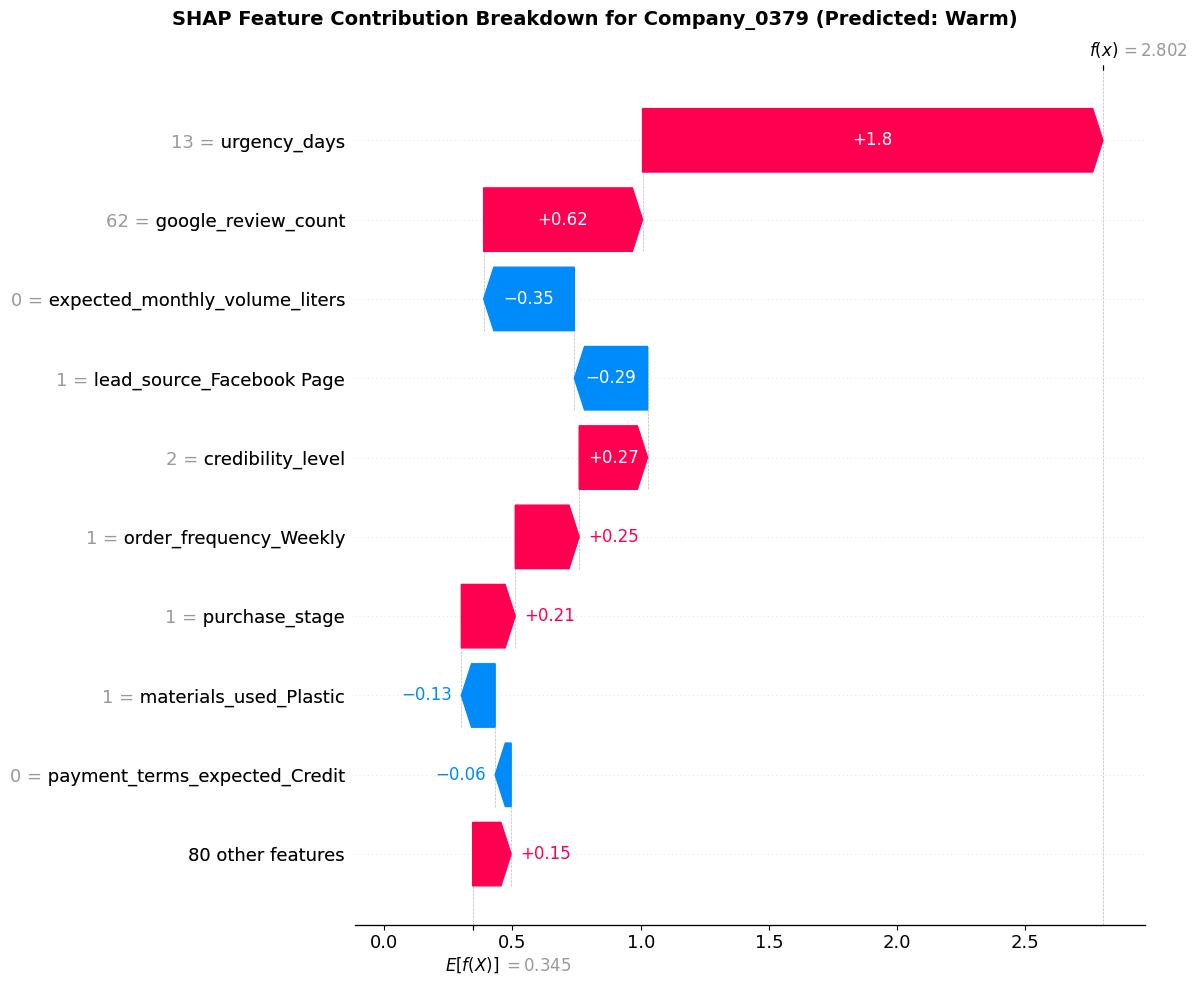

In [50]:
# selecting row index (explaining the first test company)
row_idx = 0
company_name = df.loc[X_test.index[row_idx], "company_name"]

# getting the predicted class for this company
predicted_class_idx = np.argmax(cat_tuned.predict_proba(X_test_transformed.iloc[[row_idx]]))
predicted_class_name = cat_tuned.classes_[predicted_class_idx]

# picking the SHAP values of the predicted class (the array shape depends on the SHAP version)
shap_values_array = np.array(shap_values)

if shap_values_array.ndim == 3 and shap_values_array.shape[0] == X_test_transformed.shape[0]:
    sv_row = shap_values_array[row_idx, :, predicted_class_idx]
else:
    sv_row = shap_values_array[predicted_class_idx, row_idx, :]
base_val = explainer.expected_value[predicted_class_idx]

# showing the real (unscaled) numeric values next to the features
display_row = X_test_transformed.iloc[row_idx].copy()
display_row.loc[numeric_cols] = X_test.iloc[row_idx][numeric_cols].to_numpy(dtype = float)

# building an Explanation object (the data shown next to each feature are the real, unscaled values)
explanation = shap.Explanation(
    values = sv_row,
    base_values = base_val,
    data = display_row.values,
    feature_names = feature_names_tuned
)

# displaying a waterfall chart for the predicted class
shap.plots.waterfall(explanation, show = False)

# modifying the figure
fig = plt.gcf()
fig.set_size_inches(12, 10)
fig.suptitle(f"SHAP Feature Contribution Breakdown for {company_name} (Predicted: {predicted_class_name})", fontsize = 14, fontweight = "bold")
plt.tight_layout()
plt.show()

<div style = "text-align: justify;">

**Interpretation of the Graph:**
* This waterfall explains one lead (**Company_0379**, predicted **Warm**). The model starts from its average score of **0.345**, and each feature then pushes the score up (red) or down (blue) until it reaches **2.802**.
* The scores are raw model scores, not probabilities, so higher means more likely Warm. The number beside each feature is this lead's actual value (1 = yes for yes/no features, and 0, 1, 2 run from low to high for ordered ones).

**Key Insights:**
* **Urgency** decides this prediction. A need within **13 days** adds **+1.8**, about three-quarters of the total rise from 0.345 to 2.802.
* **Reviews** and **trust** add smaller boosts: **62 Google reviews** (**+0.62**), a high `credibility_level` (**+0.27**), weekly ordering (**+0.25**) and a Regular Reorder `purchase_stage` (**+0.21**).
* **A few features pull the score down:** no volume provided (listed as **0 liters**, **−0.35**), the Facebook Page lead source (**−0.29**), plastic as a material (**−0.13**) and payment terms (**−0.06**).
* Even with no volume provided, strong urgency and reviews are enough to put this lead in Warm. The other 80 features add only **+0.15** together.
</div>

<div style = "text-align: justify;">

#### Top Feature Insights (Combined Across CatBoost Feature Importance, SHAP Average Impact, and SHAP Waterfall)

Across the **three** explanation lenses—CatBoost's built-in importance, SHAP average impact (global), and a SHAP waterfall (individual case)—the same story emerges: **lead urgency** drives prioritization, **expected demand** and **business footprint** add commercial value, and **credibility** and **intent signals** refine decisions rather than override the core drivers.

* **Urgency is the dominant driver:** `urgency_days` ranks first in both CatBoost importance (**34.8%**) and SHAP impact. In the waterfall example, a need within **13 days** supplies about three-quarters of the lead's rise towards Warm (**+1.8**), so a sooner-than-typical need pushes leads toward **Hot/Warm**.

* **Volume and reviews form the second tier:** `expected_monthly_volume_liters` (**20.8%**) and `google_review_count` (**15.4%**) join urgency to make up about **71%** of the total importance. In SHAP they act mostly on the **Reject** bucket. In the waterfall, **62 reviews** add **+0.62** to the Warm score, while missing volume (recorded as **0 liters**) subtracts **0.35**. Since 0 is used when volume is not provided, part of this feature's importance reflects whether volume was given at all.

* **Buying intent and trust nudge decisions:** `credibility_level` (**4.1%**) and `purchase_stage` (**2.8%**) take fourth and fifth place in both methods (their order swaps between them), with far smaller impact than the top three.

* **Operational and contactability features make small adjustments:** `distance_km`, `has_phone_Yes`, `order_frequency_Weekly` and the lead source each hold only about **1–2%** of the importance, acting as tie-breakers rather than drivers.

* **Zero volume means *not provided*:** 12.7% of leads (382 of 3,000) have `expected_monthly_volume_liters = 0`, and 78% of those still order weekly or monthly. The model treats this as its own group, so a lead with no volume entered is scored as a low-volume lead.

**Key Takeaway:**  
Lead qualification in this model is **urgency-led** and **value-shaped**. Credibility and intent signals add smaller nudges, while operational factors fine-tune decisions without driving them. This dependence is strong: in a separate ablation, removing `urgency_days` lowered the cross-validated Macro F1 from **0.785** to **0.600**, so the model's quality relies on urgency being recorded accurately for every lead.

</div>

### **Model Performance Summary & Insights**

First, let us summarize the final tuned CatBoost performance metrics:

| **Metric** | **Test/CV Performance** |
|------------|----------------------------|
| ***Macro F1 (Test)*** | **78.72%** |
| ***Macro F1 (Train)*** | **86.13%** |
| ***Overall Accuracy (Test)*** | **79.22%** |
| ***Cross-Validation Macro F1 (New Folds, Mean ± Std)*** | **0.7754 ± 0.0143** |
| ***OVR ROC-AUC (Macro)*** | **95.55%** |
| ***OVR ROC-AUC (Weighted)*** | **95.04%** |
| ***Qualified-vs-Not ROC-AUC*** | **99.08%** |
| ***Hot Recall (Test)*** | **76%** |
| ***Warm Recall (Test)*** | **85%** |
| ***Train–Test Macro F1 Difference (Overfitting*)*** | **7.41%** |
| ***Overfitting Status*** | **Good** |
| ***Best Tuned Parameters (Optuna TPE)*** | `iterations = 900`, `learning_rate = 0.024`, `depth = 4`, `l2_leaf_reg = 1.23`, `subsample = 0.65`, `rsm = 0.59`, `random_strength = 3.32`, `auto_class_weights = None` |

***Overfitting criteria (based on Train–Test Macro F1 gap):** Good (<10%), Moderate (10–20%), High (>20%)

<div style="text-align: justify;">

#### Detailed Insights

1. **Macro F1 (Test): 78.72%**. The model performs well across all five buckets rather than leaning on the largest ones. **Reject** (F1 0.87) and **Warm** (0.85) are the strongest, while **Cold** (0.74) and **Save For Later** (0.72) are the weakest, with recalls of 0.71 and 0.67.

2. **Overfitting (Train–Test Gap): 7.41% (Good)**. Tuning cut the gap from **21.61%** (base CatBoost) to **7.41%**, which is now inside the Good range. Some gap remains (train 86.13% vs test 78.72%), so the model still fits the training data a little better than new data.

3. **Cross-Validation Macro F1: 0.7754 ± 0.0143**. This was measured on a different set of folds (the same training rows, so still slightly optimistic), and it agrees with the test score. The 0.7852 from the tuning run is the best of 60 trials, so it is slightly optimistic. The gain over the base model (0.7714) is small and within fold-to-fold noise, so the real benefit of tuning is lower overfitting rather than a higher score.

4. **ROC-AUC (OVR Macro: 95.55%, OVR Weighted: 95.04%, Qualified-vs-Not: 99.08%)**. The model separates each class from the rest very well. For the key business question, *"is this lead Hot or Warm?"*, it ranks leads almost perfectly, which is what the triage workflow needs.

5. **Hot and Warm Leads**. Hot has a precision of 0.74 and a recall of 0.76, and Warm has 0.85 on both. **Reject** recall is 0.98, so poor leads are filtered out reliably.

**Key Takeaway:**  The tuned CatBoost model gives balanced, stable performance (**Macro F1 ≈ 79%**) with controlled overfitting (**7.41% gap**) and strong lead ranking (**AUC ≈ 95–99%**). It depends heavily on `urgency_days`: in an ablation, removing it dropped the cross-validated Macro F1 from **0.785** to **0.600**, so urgency must be recorded accurately for every lead.

</div>

# **Model Deployment & Testing**

<div style = "text-align: justify;">

The **`lead_evaluator.ipynb`** notebook is used as the development workspace to clean the data, train multiple models, tune CatBoost, and evaluate performance. However, the notebook is **not** intended for day-to-day usage or business-side testing. Instead, once the final model is selected, the fitted **pipeline** (preprocessing and the tuned CatBoost model in one object) is saved as a single artifact in the [**`artifacts`**](../artifacts/) folder, together with a small `metadata.joblib` file (input columns, categories seen in training, numeric ranges, and score thresholds). Saving the pipeline as one object guarantees that new leads are encoded exactly like the training data, with no hand-copied preprocessing steps. A separate Python module, [**`pipeline.py`**](../src/pipeline.py), loads these artifacts and checks every incoming lead before scoring it: leads with missing or negative values are **not scored** and are marked *"Check data first"*, while unseen categories, out-of-range values and zero volume are scored but **flagged**. These checks matter because CatBoost reads a missing number as the smallest value, so a lead with no `urgency_days` would otherwise look like the most urgent one. Finally, [**`score_new_leads.py`**](../src/score_new_leads.py) is the lightweight testing/usage script—it reads any new company lead data (CSV), calls `predict_leads()`, and outputs the predicted **lead bucket**, computed **lead score**, recommended **action**, and any **data flag** for real-world evaluation.

</div>

## Saving the Artifacts

In [51]:
# creating a folder to store all production artifacts
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok = True)

# 1. saving the tuned pipeline (preprocessing + CatBoost in one object, fitted on the training set only)
joblib.dump(value = cat_tuned_pipe, filename = ARTIFACT_DIR / "lead_evaluator_pipeline.joblib")
print("Saved: lead_evaluator_pipeline.joblib")

# 2. collecting the categories that the fitted encoders learned (used to flag unseen values in new leads)
fitted_preprocessor = cat_tuned_pipe.named_steps["preprocess"]
category_levels = {}
for col, levels in zip(ordinal_cols, fitted_preprocessor.named_transformers_["ordinal"].categories_):
    category_levels[col] = list(levels)
for col, levels in zip(onehot_cols, fitted_preprocessor.named_transformers_["onehot"].categories_):
    category_levels[col] = list(levels)

# 3. saving the metadata dictionary
metadata = {
    "input_columns": X_train.columns.tolist(),
    "numeric_cols": numeric_cols,
    "category_levels": category_levels,
    "numeric_ranges": {col: (float(X_train[col].min()), float(X_train[col].max())) for col in numeric_cols},
    "classes": cat_tuned.classes_.tolist(),
    "qualified_thresholds": {"prioritize": 70, "nurture": 40}
}
joblib.dump(value = metadata, filename = ARTIFACT_DIR / "metadata.joblib")
print("Saved: metadata.joblib")

# verifying that all files are saved
print(
f"""{"─" * 50}
Saved with sklearn {sklearn.__version__} and catboost {catboost.__version__}
Input columns: {len(metadata["input_columns"])}
Numeric cols: {numeric_cols}
Model classes: {metadata["classes"]}
Training range of urgency_days: {metadata["numeric_ranges"]["urgency_days"]}"""
)

Saved: lead_evaluator_pipeline.joblib
Saved: metadata.joblib
──────────────────────────────────────────────────
Saved with sklearn 1.8.0 and catboost 1.2.10
Input columns: 22
Numeric cols: ['distance_km', 'expected_monthly_volume_liters', 'urgency_days', 'google_review_count']
Model classes: ['Cold', 'Hot', 'Reject', 'Save For Later', 'Warm']
Training range of urgency_days: (1.0, 89.0)


# **Conclusion**

<div style="text-align: justify;">

This project delivered a proof-of-concept **Lead Evaluator** for Swan Chemical Ltd. that converts raw lead information into **actionable sales decisions**. Using a dataset of operational signals (distance, urgency, expected demand), credibility indicators (reviews, contact availability) and commercial intent variables (purchase stage, payment expectations), the system classifies each lead into one of five business-ready buckets: **Hot, Warm, Cold, Save For Later,** or **Reject**.

Five multi-class models were compared on **cross-validated Macro F1**, with preprocessing learned inside each fold and the test set not used for tuning. **CatBoost** was selected and tuned with Optuna, reaching a **Macro F1 of 78.72%** and **79.22% accuracy** on the held-out test set. Tuning cut the train–test gap from **21.61% to 7.41%**, and the model separates qualified (Hot/Warm) from unqualified leads with an **AUC of 99.08%**. Explainability analysis showed the model is **urgency-led**: `urgency_days` drives the predictions, followed by expected volume and Google reviews, and removing urgency lowers cross-validated Macro F1 from 0.785 to 0.600. Beyond classification, the project defined a probability-based **QualifiedScore** (P(Hot) + P(Warm)) and mapped it into simple actions—**prioritize**, **nurture**, or **deprioritize**.

For real usage, the fitted pipeline is saved as a single artifact and run through a lightweight scoring script that also checks incoming data, so leads with missing or impossible values are flagged instead of being scored misleadingly. The main limitations are the dependence on accurate urgency data, the use of a synthetic dataset, and action thresholds that are a starting point. Once real lead outcomes are available, the model and thresholds should be re-validated and recalibrated. Even so, the project demonstrates a realistic MVP that can help the sales team spend less time on low-quality leads and qualify leads in a consistent, repeatable way.

</div>